# 시간대별 렉 방문 집중도 · 조회 기간별

`layout_2026-09` 위에 **시간대별로 많이 방문한 렉은 진하게, 적게 방문한 렉은 연하게** 칠합니다.
`PERIODS`의 조회 기간마다 같은 계산을 하고, 결과를 기간별 디렉토리에 나눠 저장합니다.

- 조회 기간: 현재 레이아웃과 코드 체계가 맞는 **2026-08-10 이후**만 사용합니다.
  기본값은 8/10~8/31, 9/1~9/27입니다. 9월 자료는 9/27에서 끝납니다.
- 대상: 출고 요청 시각이 기간 안이고 `SHIPPED`, `pickingQuantity > 0`인 행.
- **방문 1회 = 주문 1건이 그 렉에서 1번 이상 피킹.** 같은 주문이 한 렉의 여러 층·선반에서
  피킹해도 1회로 셉니다. 할당된 로케이션 기준이며 실제 걸은 경로가 아닙니다.
- 시간대는 `outboundRequestDateTime`(출고 요청 시각)의 시각입니다. 실제 피킹 시각이 아닙니다.
- **색 = 그 시간대 전체 방문 중 해당 렉의 비중(%)**. 모든 기간·시간대가 같은 색 척도를 씁니다.
  전체 비중 분포의 99번째 백분위 이상은 가장 진한 색으로 묶습니다.
- 방문이 없는 렉은 흰 칸, `~` 자리는 사선 빗금, 기둥은 회색 X 빗금, 도면 밖은 회색입니다.
- A·B·C_D는 서로 독립 좌표의 도면입니다.

**출력:** `reports/mfc_rack_visits_by_hour/<시작일>_<종료일>/`
- `visits_<시간대>.png`: 시간대별 지도와 전체 지도
- `rack_visits.csv`: 렉 × 시간대 방문 횟수와 비중(%)
- `summary.csv`: 시간대별 주문 수·방문 수·방문 렉 수·상위 10% 렉 비중
- `top10.csv`: 시간대별 상위 10개 렉
- `meta.json`: 조회 조건과 실제 관측 기간

[레이아웃 설명](../docs/mfc_layout_array.md) · [운영 context](../docs/mfc_operating_context.md)

In [1]:
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, Normalize
from matplotlib.patches import Rectangle

from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.mfc_layout import load_layout

ROOT = find_project_root()
OUTPUT = ROOT / "reports/mfc_rack_visits_by_hour"
fonts = {font.name for font in font_manager.fontManager.ttflist}
for font in ("AppleGothic", "Malgun Gothic", "NanumGothic"):
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "#f8fafc"

layout = load_layout("2026-09")
TITLES = {"A": "A · 냉동", "B": "B · 냉장", "C_D": "C·D · 상온"}
# 단일 색상(빨강) 연속 척도: 연함 = 적은 방문, 진함 = 많은 방문
REDS = LinearSegmentedColormap.from_list("visits", [
    "#fde4e3", "#f9bcb9", "#f28d8a", "#e34948", "#c42e2e", "#981b1e", "#6a1013"])

## 1. 조회 기간·시간대 정의와 방문 집계

`PERIODS`에 `(시작일, 종료일)`을 추가하면 같은 방식으로 계산합니다. 종료일도 포함합니다.
레이아웃 버전이 `2026-09`이므로 2026-08-10 이전 기간은 막아 둡니다.
`HOUR_BANDS`를 바꾸면 시간대 구간이 바뀝니다. 00시 요청은 22~24시 구간에 넣습니다.

In [2]:
SOURCE = ROOT / "outbound_2026-06-01_2026-09-27_2026-09-28_1152.csv"
LAYOUT_VALID_FROM = "2026-08-10"
PERIODS = [("2026-08-10", "2026-08-31"), ("2026-09-01", "2026-09-27")]
HOUR_BANDS = {  # 이름: 포함할 요청 시각(시)
    "07–10시": [7, 8, 9], "10–13시": [10, 11, 12], "13–16시": [13, 14, 15],
    "16–19시": [16, 17, 18], "19–22시": [19, 20, 21], "22–24시(+00시)": [22, 23, 0],
}
hour_to_band = {hour: band for band, hours in HOUR_BANDS.items() for hour in hours}
placed = set(layout.racks.index[layout.racks["observed"]])


def load_picks(start, end):
    assert start >= LAYOUT_VALID_FROM, "현재 레이아웃 이전 기간입니다."
    picks = duckdb.sql(f"""
        select "orderId(주문번호)" as order_id,
               cast(outboundRequestDateTime as timestamp) as requested_at,
               regexp_extract(locationCode, '^([ABCD]\\d{{2}}-\\d{{2}})-\\d+$', 1) as rack_code
        from read_csv('{SOURCE}', all_varchar = true)
        where status = 'SHIPPED'
          and cast(outboundRequestDateTime as timestamp) >= '{start}'
          and cast(outboundRequestDateTime as timestamp) < date '{end}' + interval 1 day
          and cast(pickingQuantity as integer) > 0
    """).df()
    picks["band"] = picks["requested_at"].dt.hour.map(hour_to_band)
    assert picks["band"].notna().all(), "HOUR_BANDS에 없는 시각이 있습니다."
    picks["on_map"] = picks["rack_code"].isin(placed)
    return picks


def aggregate(picks):
    visits = picks.loc[picks["on_map"], ["order_id", "band", "rack_code"]].drop_duplicates()
    counts = visits.groupby(["band", "rack_code"]).size().unstack("band", fill_value=0)
    counts = counts.reindex(index=sorted(placed), columns=list(HOUR_BANDS), fill_value=0)
    counts["전체"] = counts.sum(axis=1)
    shares = counts / counts.sum() * 100
    orders = picks.groupby("band")["order_id"].nunique().reindex(list(HOUR_BANDS))
    orders["전체"] = picks["order_id"].nunique()
    summary = pd.DataFrame({
        "주문 수": orders, "렉 방문": counts.sum(), "방문 렉 수": (counts > 0).sum(),
        "상위 10% 렉의 방문 비중(%)": [
            shares[c].nlargest(len(placed) // 10).sum().round(1) for c in counts.columns],
    })
    return {"picks": picks, "counts": counts, "shares": shares, "summary": summary}


results = {}
for start, end in PERIODS:
    picks = load_picks(start, end)
    results[(start, end)] = aggregate(picks)
    print(f"{start}~{end} · 관측 {picks['requested_at'].min()} ~ {picks['requested_at'].max()} · "
          f"주문 {picks['order_id'].nunique():,}건 · 지도 표시 행 {picks['on_map'].mean():.1%}")

# 모든 기간·시간대가 같은 색 척도를 쓰도록 한 번에 정합니다.
all_shares = np.concatenate([r["shares"][list(HOUR_BANDS)].to_numpy().ravel()
                             for r in results.values()])
NORM = Normalize(vmin=0, vmax=np.percentile(all_shares, 99), clip=True)
print(f"색 척도 상한: {NORM.vmax:.2f}%")

2026-08-10~2026-08-31 · 관측 2026-08-10 07:43:06 ~ 2026-08-31 23:59:07 · 주문 30,042건 · 지도 표시 행 98.9%


2026-09-01~2026-09-27 · 관측 2026-09-01 07:43:02 ~ 2026-09-27 23:59:41 · 주문 32,650건 · 지도 표시 행 99.1%
색 척도 상한: 0.85%


## 2. 지도 그리기와 기간별 저장

각 시간대 상위 5개 렉에는 코드와 비중을 직접 표시합니다.

In [3]:
def draw_area(ax, area, shares, column):
    grid = layout.grids[area]
    # 기둥은 진한 색과 헷갈리지 않도록 회색 빗금으로 그립니다.
    background = np.where(np.isin(grid, list(".#")), 0, 1)
    ax.imshow(background, cmap=ListedColormap(["#ffffff", "#e7e5e4"]),
              vmin=0, vmax=1, interpolation="nearest")
    for row, col in zip(*np.nonzero(grid == "#")):
        ax.add_patch(Rectangle((col - 0.5, row - 0.5), 1, 1, facecolor="#d6d3d1",
                               edgecolor="#57534e", linewidth=0.6, hatch="xxx"))
    racks = layout.racks.loc[layout.racks["area"].eq(area)]
    for code, cell in racks.iterrows():
        if not cell.observed:
            face, hatch = "#fafafa", "//"
        else:
            share = shares.at[code, column]
            face, hatch = ("#ffffff" if share == 0 else REDS(NORM(share))), None
        ax.add_patch(Rectangle((cell.x, cell.y), cell.width, cell.height, facecolor=face,
                               edgecolor="#94a3b8", linewidth=0.4, hatch=hatch))
    ax.set(xlim=(-0.5, grid.shape[1] - 0.5), ylim=(grid.shape[0] - 0.5, -0.5))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(TITLES[area], fontsize=13)


def show_band(period, column, top=5, folder=None):
    result = results[period]
    shares, counts, summary = result["shares"], result["counts"], result["summary"]
    fig, axes = plt.subplots(1, 3, figsize=(24, 10), layout="constrained",
                             width_ratios=[g.shape[1] for g in layout.grids.values()])
    for ax, area in zip(axes, layout.grids):
        draw_area(ax, area, shares, column)
    for code in shares[column].nlargest(top).index:
        cell = layout.racks.loc[code]
        ax = axes[list(layout.grids).index(cell.area)]
        ax.annotate(f"{code}\n{shares.at[code, column]:.2f}%", (cell.cx, cell.cy),
                    xytext=(8, 8), textcoords="offset points", fontsize=8.5,
                    fontweight="bold", color="#0f172a", zorder=4,
                    arrowprops={"arrowstyle": "-", "color": "#475569", "lw": 0.8},
                    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none", "pad": 1.5})
    bar = fig.colorbar(plt.cm.ScalarMappable(norm=NORM, cmap=REDS), ax=axes,
                       location="bottom", shrink=0.35, pad=0.02, extend="max")
    bar.set_label("해당 시간대 전체 방문 중 렉 비중(%) · 흰색 = 방문 없음", fontsize=11)
    fig.suptitle(f"렉 방문 집중도 · {period[0]} ~ {period[1]} · {column}\n"
                 f"주문 {summary.at[column, '주문 수']:,}건 · 렉 방문 {counts[column].sum():,}회 · "
                 f"상위 {top}개 렉 표시 · 할당 로케이션 기준", fontsize=16)
    if folder is not None:
        name = column.split("(")[0].replace("–", "-")
        fig.savefig(folder / f"visits_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_period(period):
    result = results[period]
    folder = OUTPUT / f"{period[0]}_{period[1]}"
    folder.mkdir(parents=True, exist_ok=True)
    counts, shares, picks = result["counts"], result["shares"], result["picks"]
    table = counts.add_suffix("_방문").join(shares.round(4).add_suffix("_비중(%)"))
    table.join(layout.racks[["area", "zone", "aisle", "rack", "placement"]]) \
        .rename_axis("rack_code").to_csv(folder / "rack_visits.csv", encoding="utf-8-sig")
    result["summary"].rename_axis("시간대").to_csv(folder / "summary.csv", encoding="utf-8-sig")
    top10 = pd.DataFrame({c: [f"{code} ({shares.at[code, c]:.2f}%)"
                              for code in shares[c].nlargest(10).index]
                          for c in counts.columns}, index=pd.RangeIndex(1, 11, name="순위"))
    top10.to_csv(folder / "top10.csv", encoding="utf-8-sig")
    meta = {
        "query_start": period[0], "query_end_inclusive": period[1],
        "observed_first_request": str(picks["requested_at"].min()),
        "observed_last_request": str(picks["requested_at"].max()),
        "source": SOURCE.name, "layout_version": layout.version,
        "filters": "status=SHIPPED, pickingQuantity>0, outboundRequestDateTime 기준",
        "visit_definition": "주문-렉 쌍 1회. 층·선반 무시. 할당 로케이션 기준",
        "hour_bands": HOUR_BANDS, "color_vmax_share_pct": round(float(NORM.vmax), 4),
        "orders": int(picks["order_id"].nunique()), "pick_rows": len(picks),
        "on_map_row_share": round(float(picks["on_map"].mean()), 4),
    }
    (folder / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2) + "\n",
                                      encoding="utf-8")
    for column in counts.columns:
        show_band(period, column, folder=folder)
    return folder

## 3. 기간별 실행

각 기간의 요약표와 시간대별 상위 10개 렉을 표시하고 지도를 저장합니다.

findfont: Failed to find font weight bold for AppleGothic, now using 400.


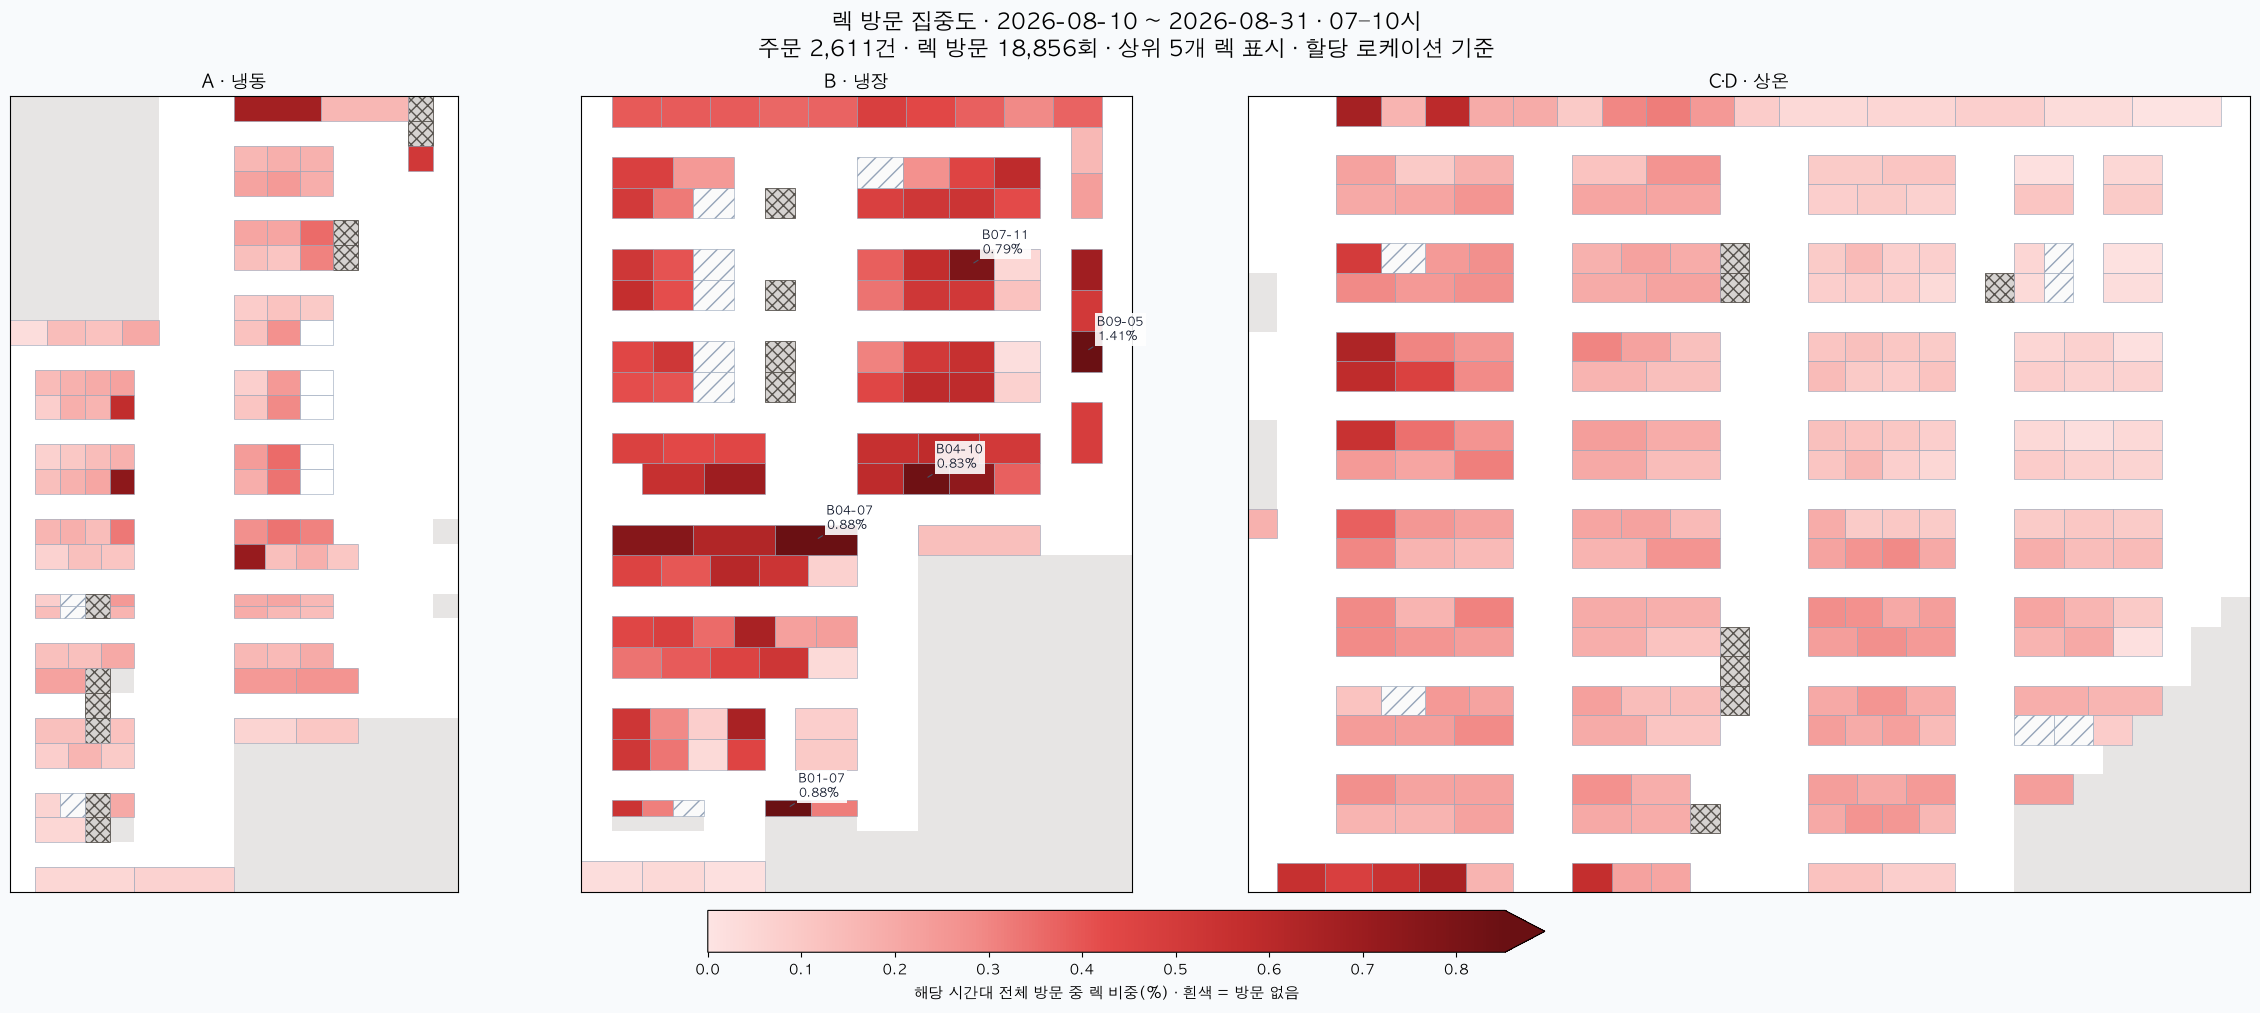

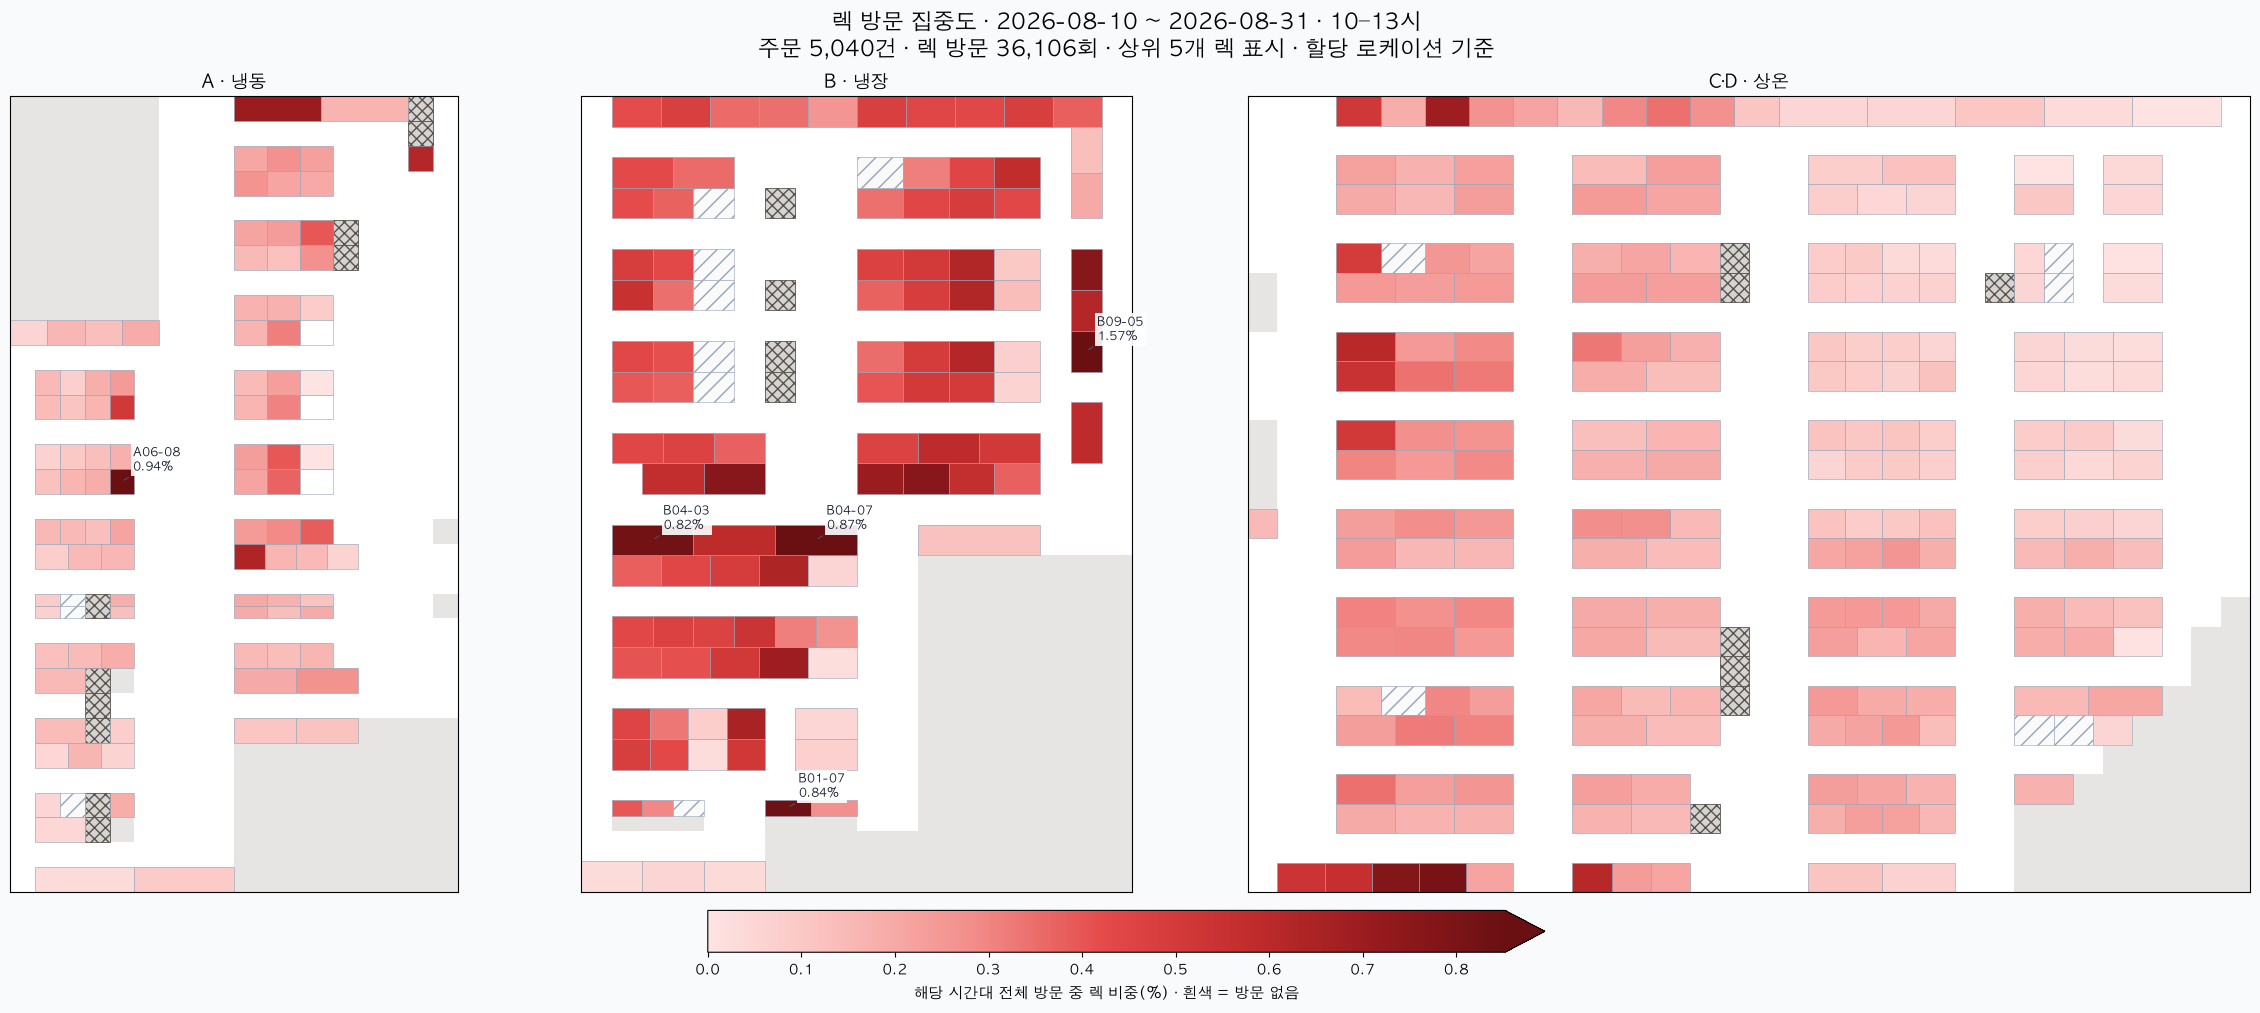

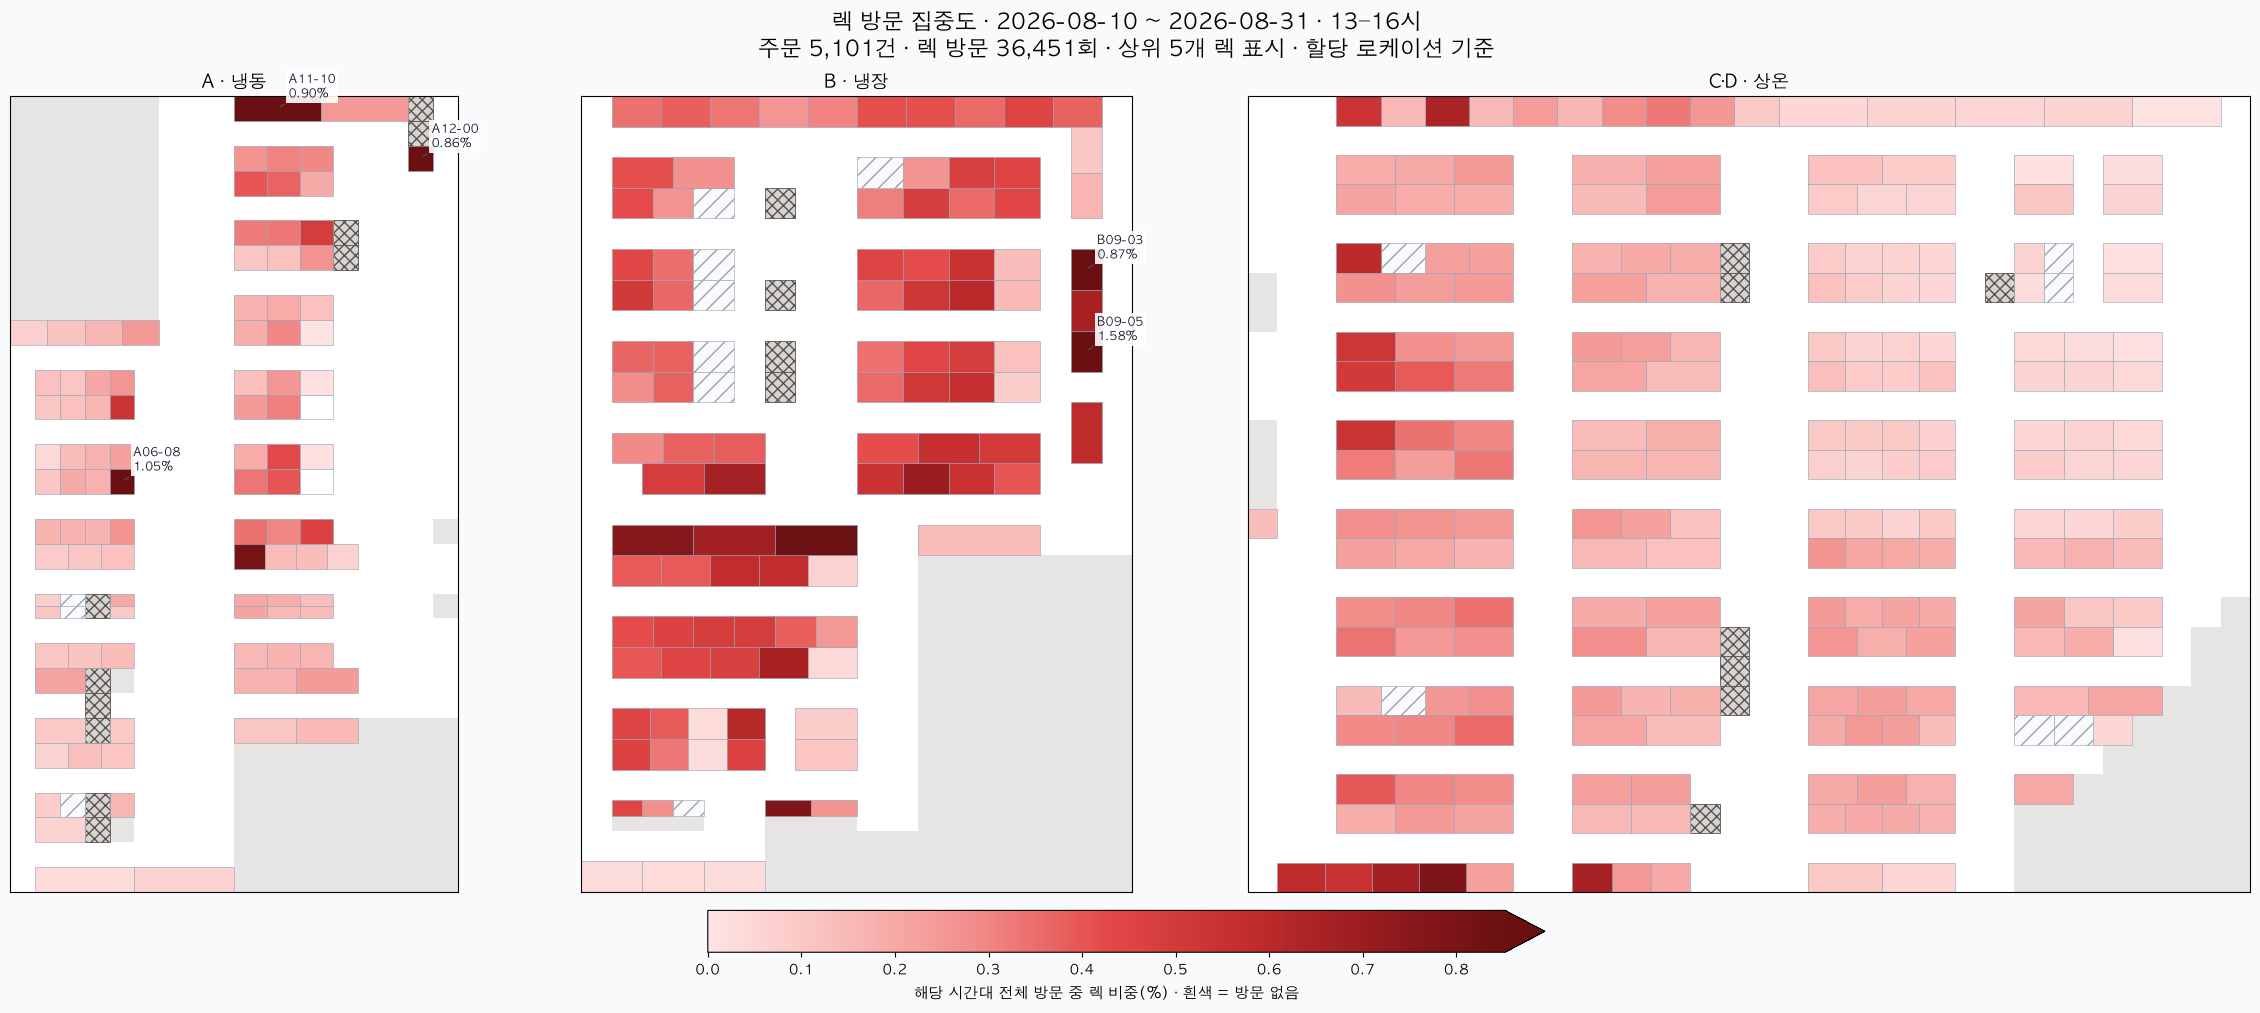

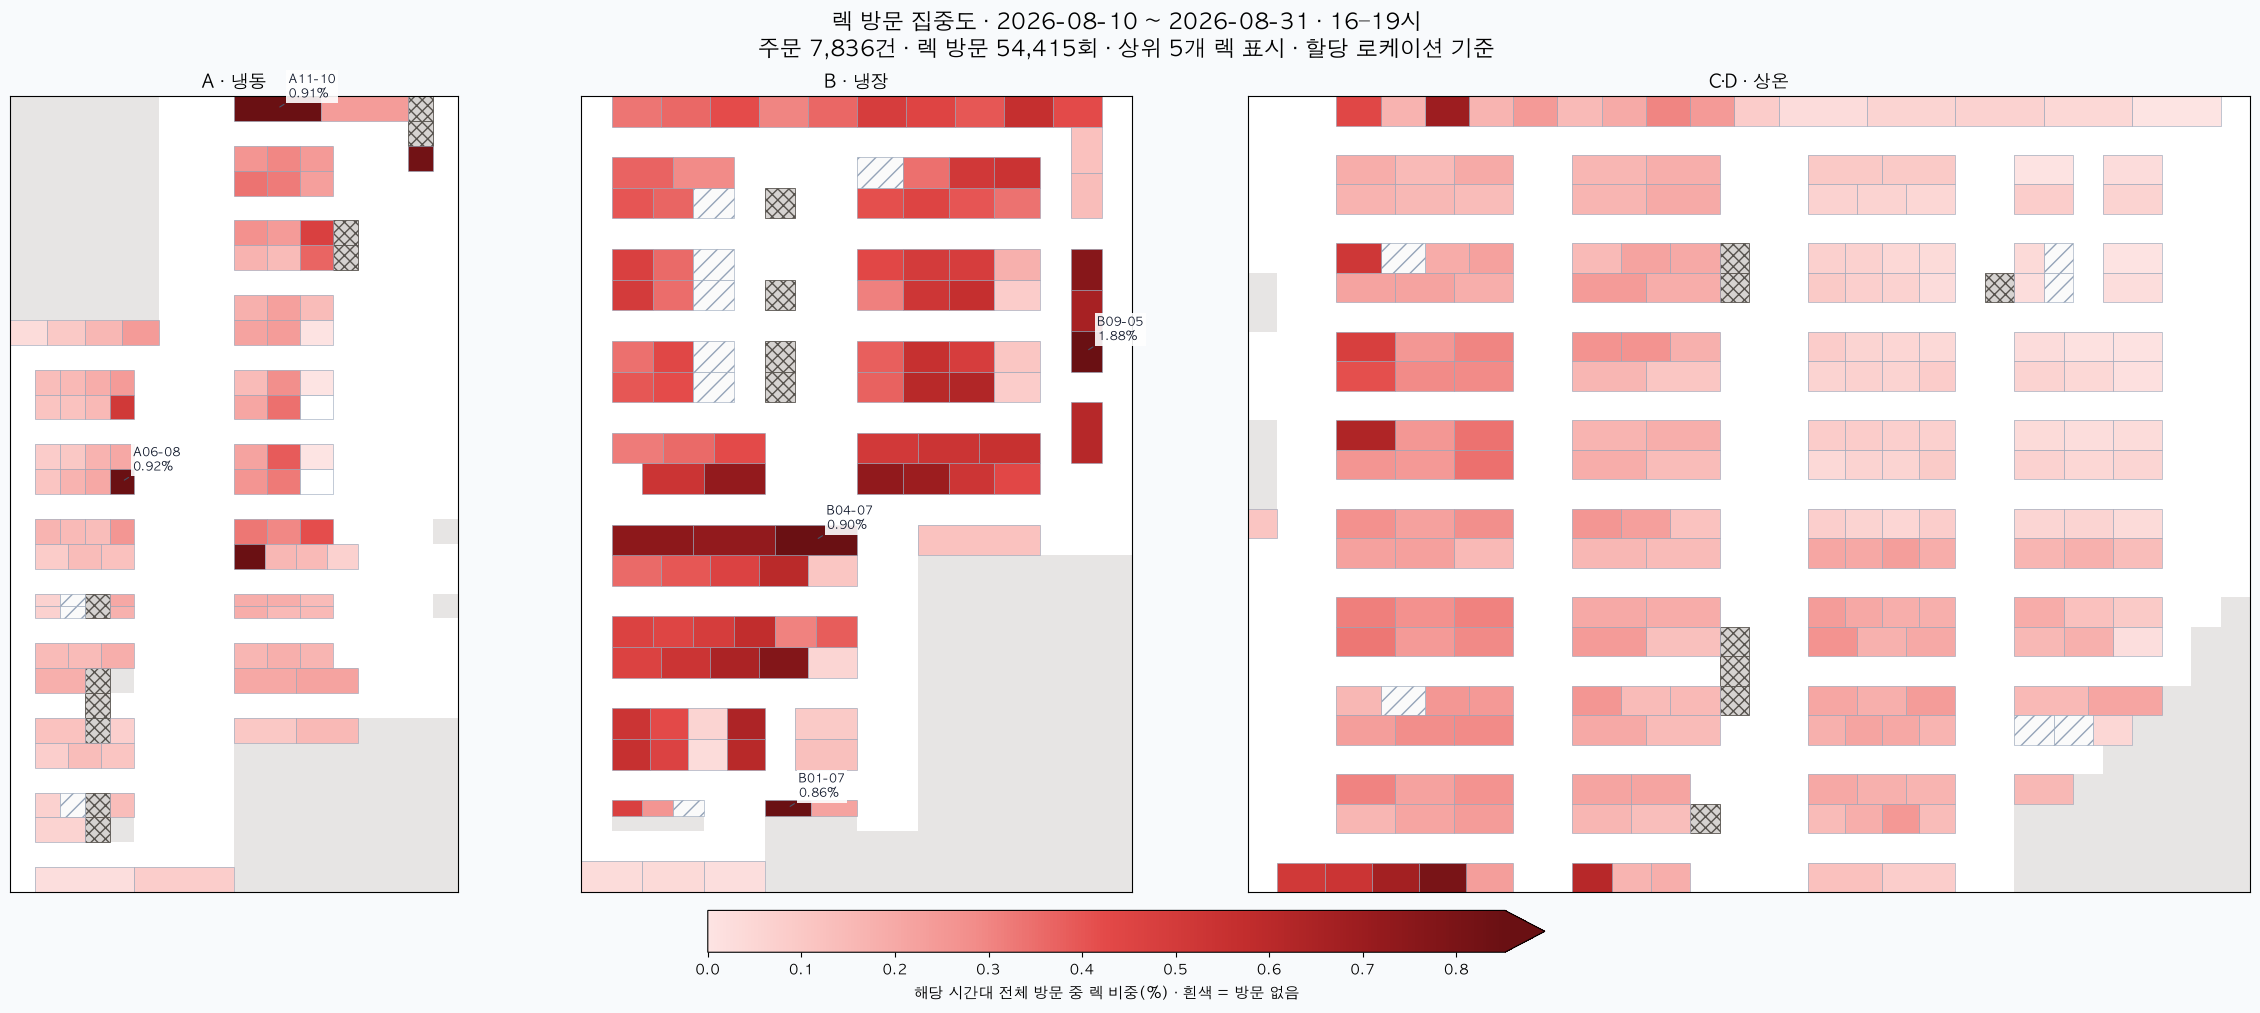

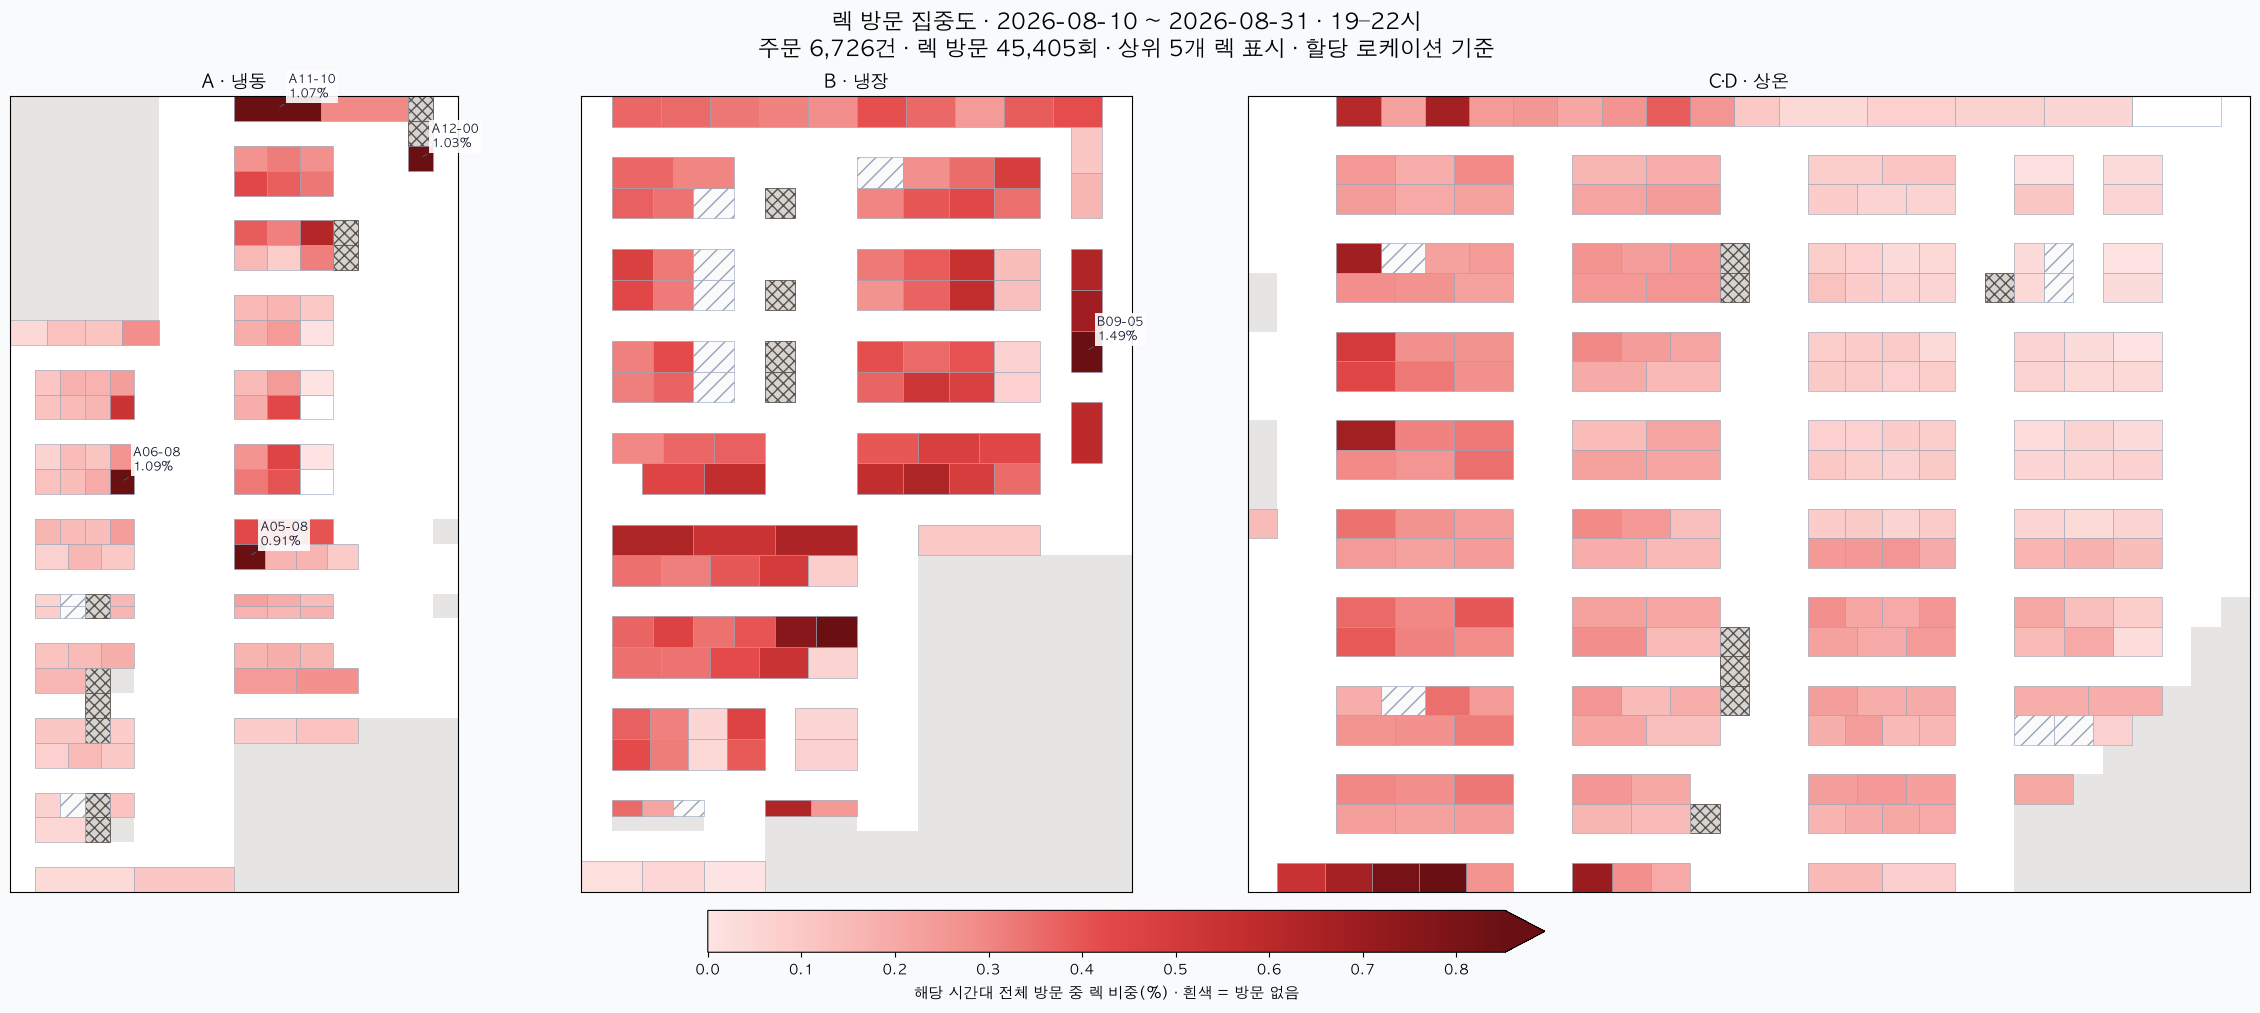

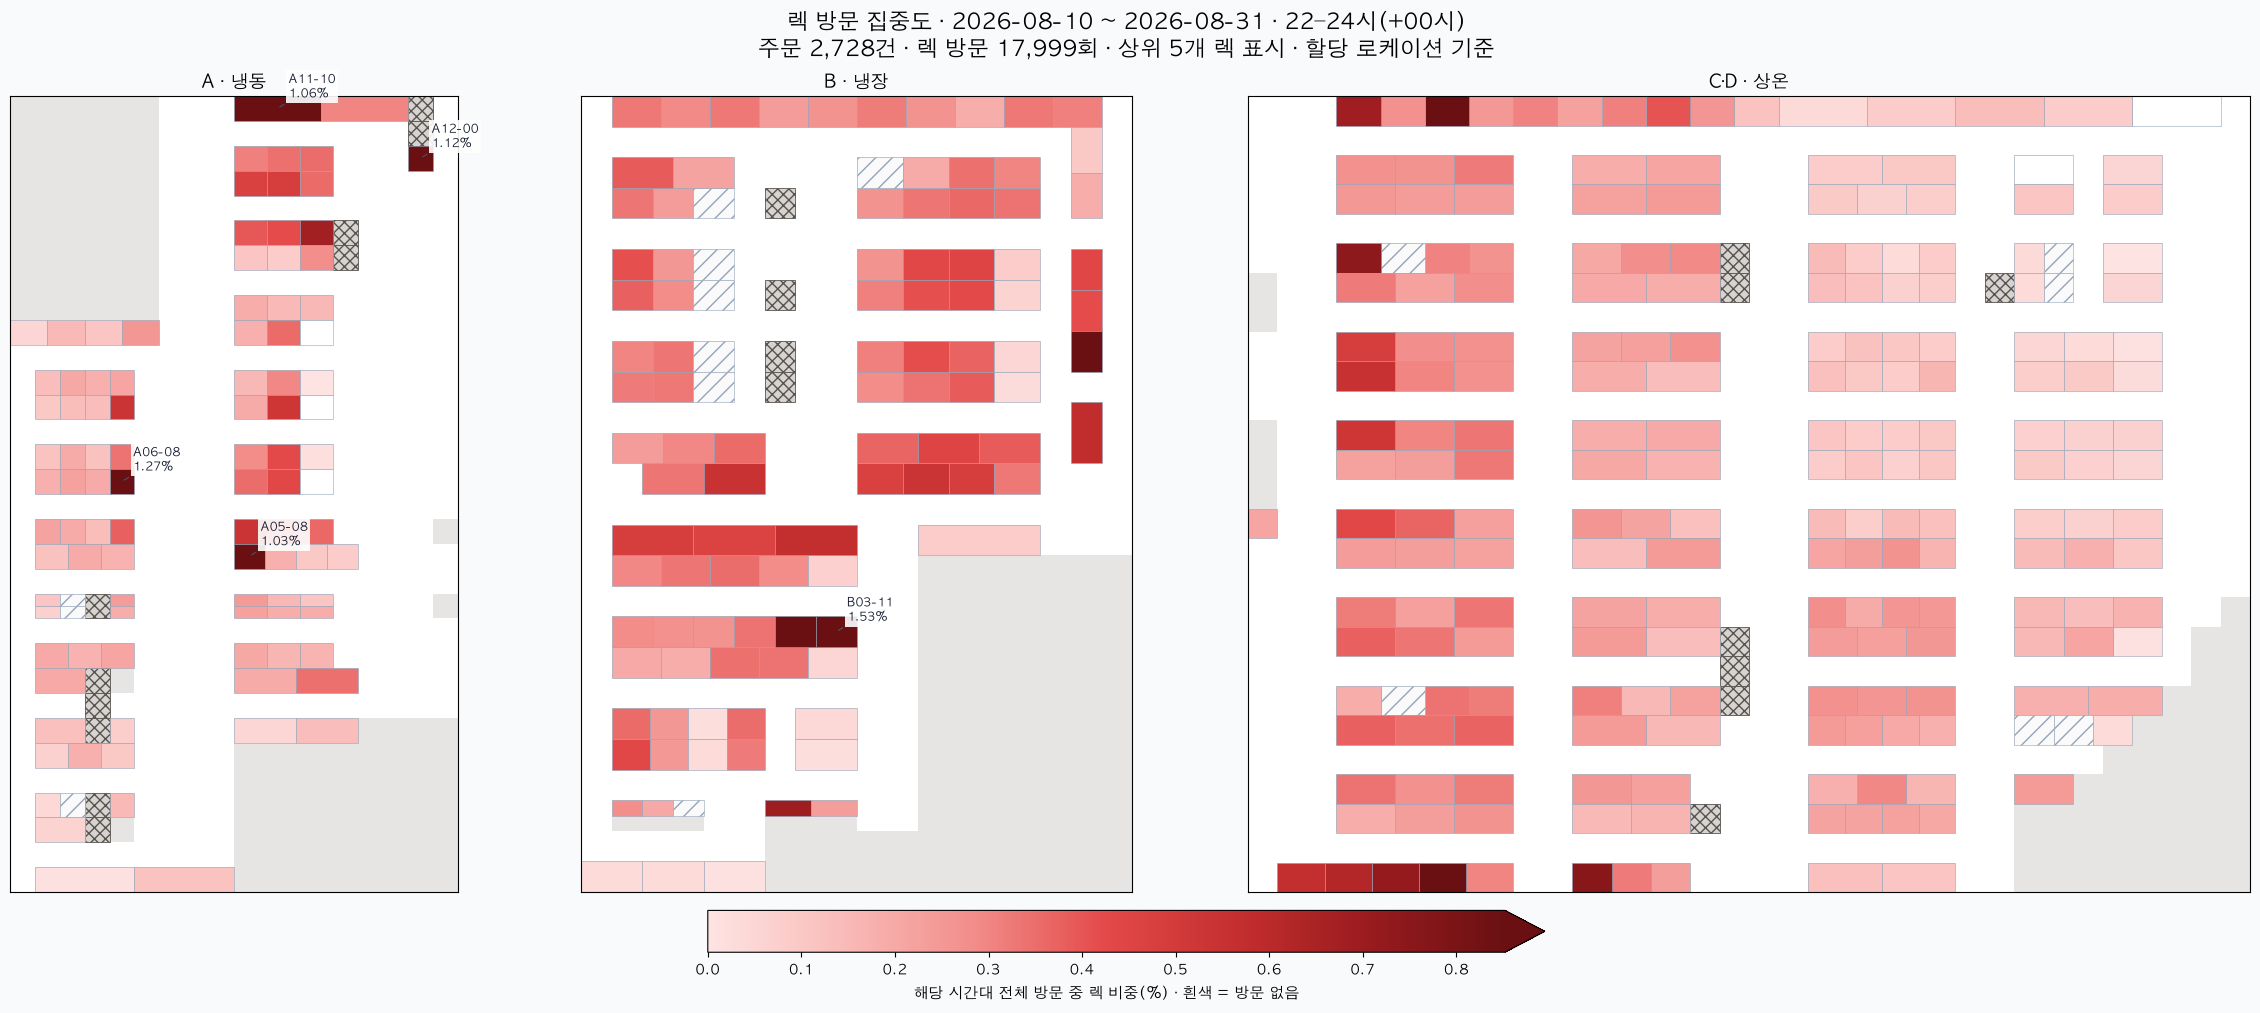

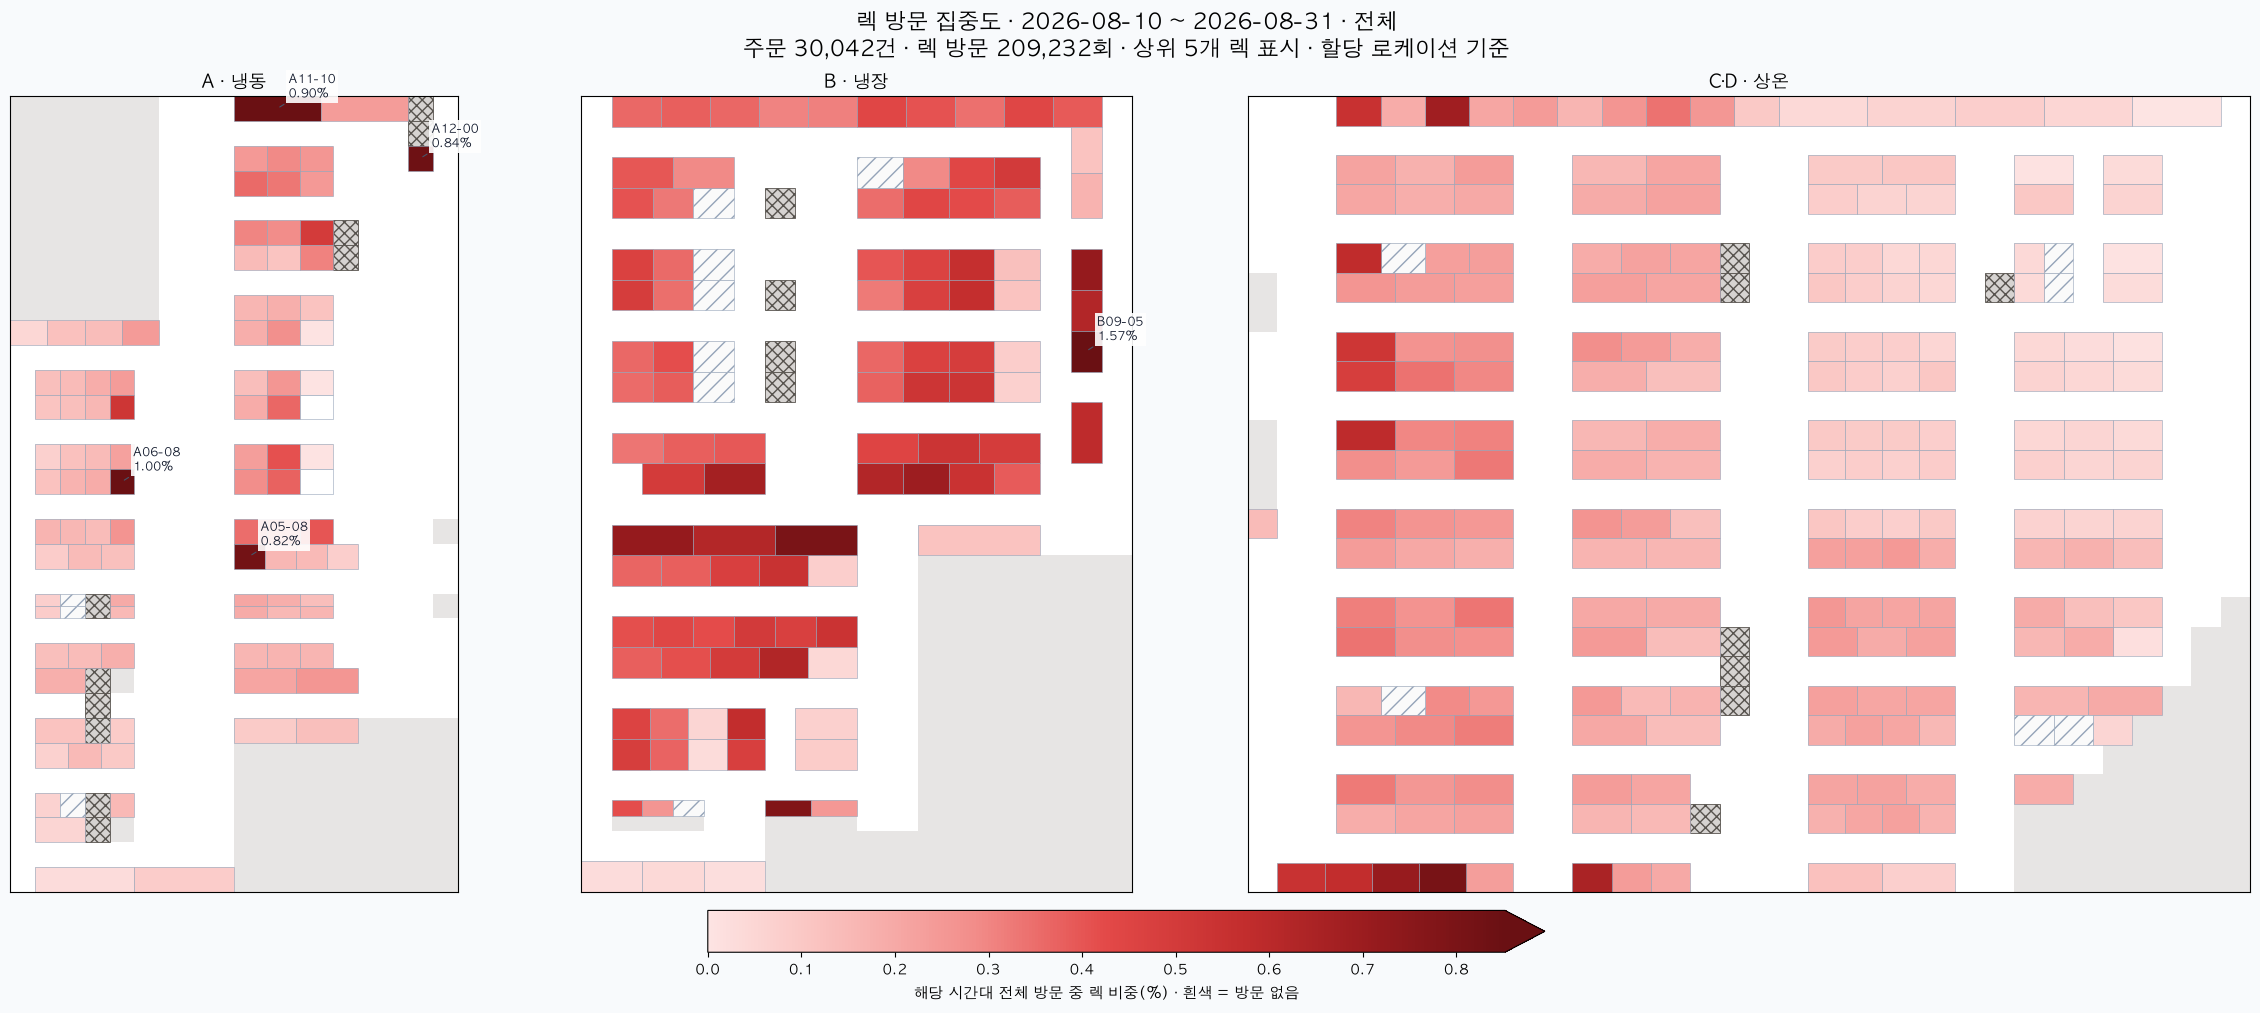

저장: reports/mfc_rack_visits_by_hour/2026-08-10_2026-08-31


,주문 수,렉 방문,방문 렉 수,상위 10% 렉의 방문 비중(%)
band,,,,
07–10시,2611,18856,397,26.1
10–13시,5040,36106,399,26.7
13–16시,5101,36451,400,26.7
16–19시,7836,54415,400,27.8
19–22시,6726,45405,399,26.8
22–24시(+00시),2728,17999,397,26.6
전체,30042,209232,400,26.3


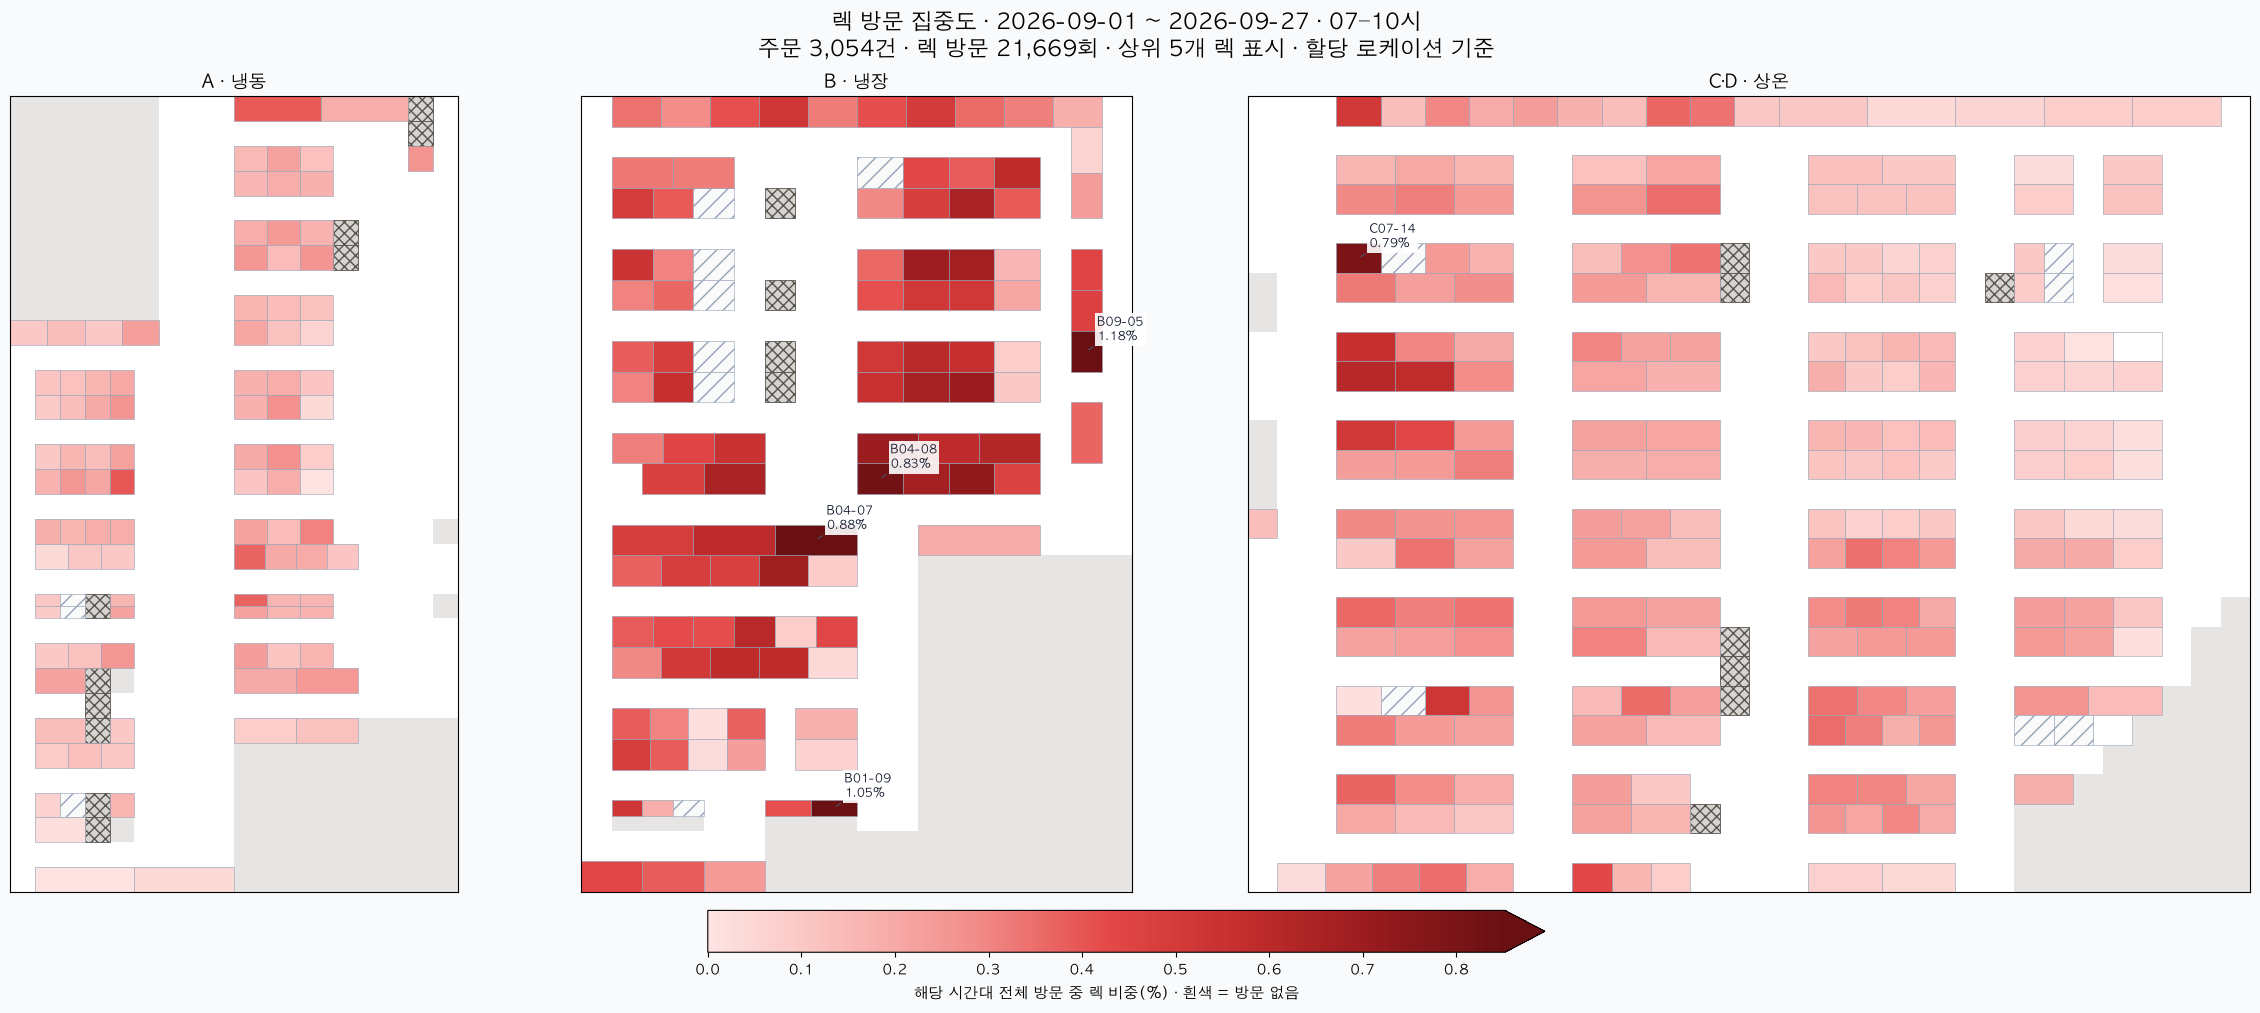

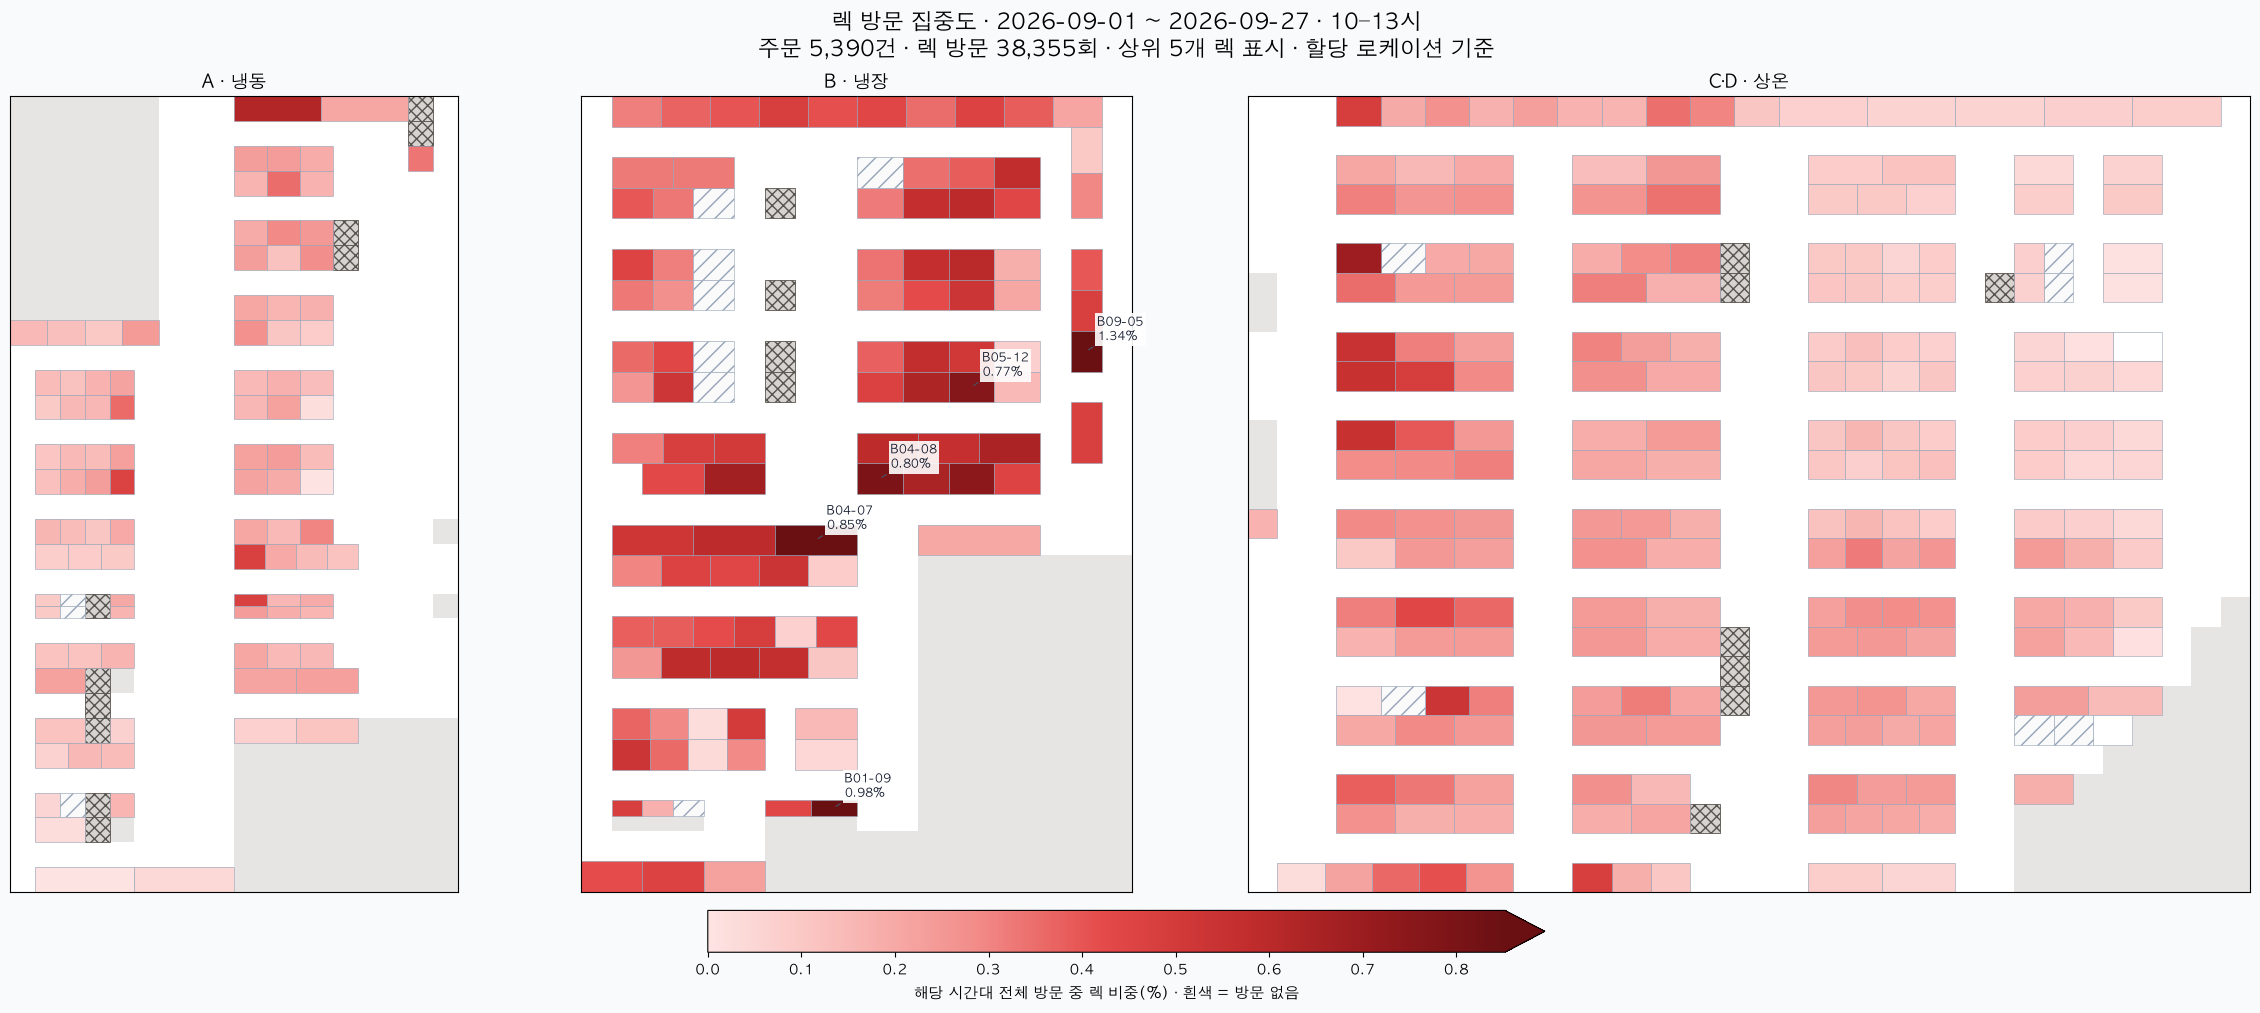

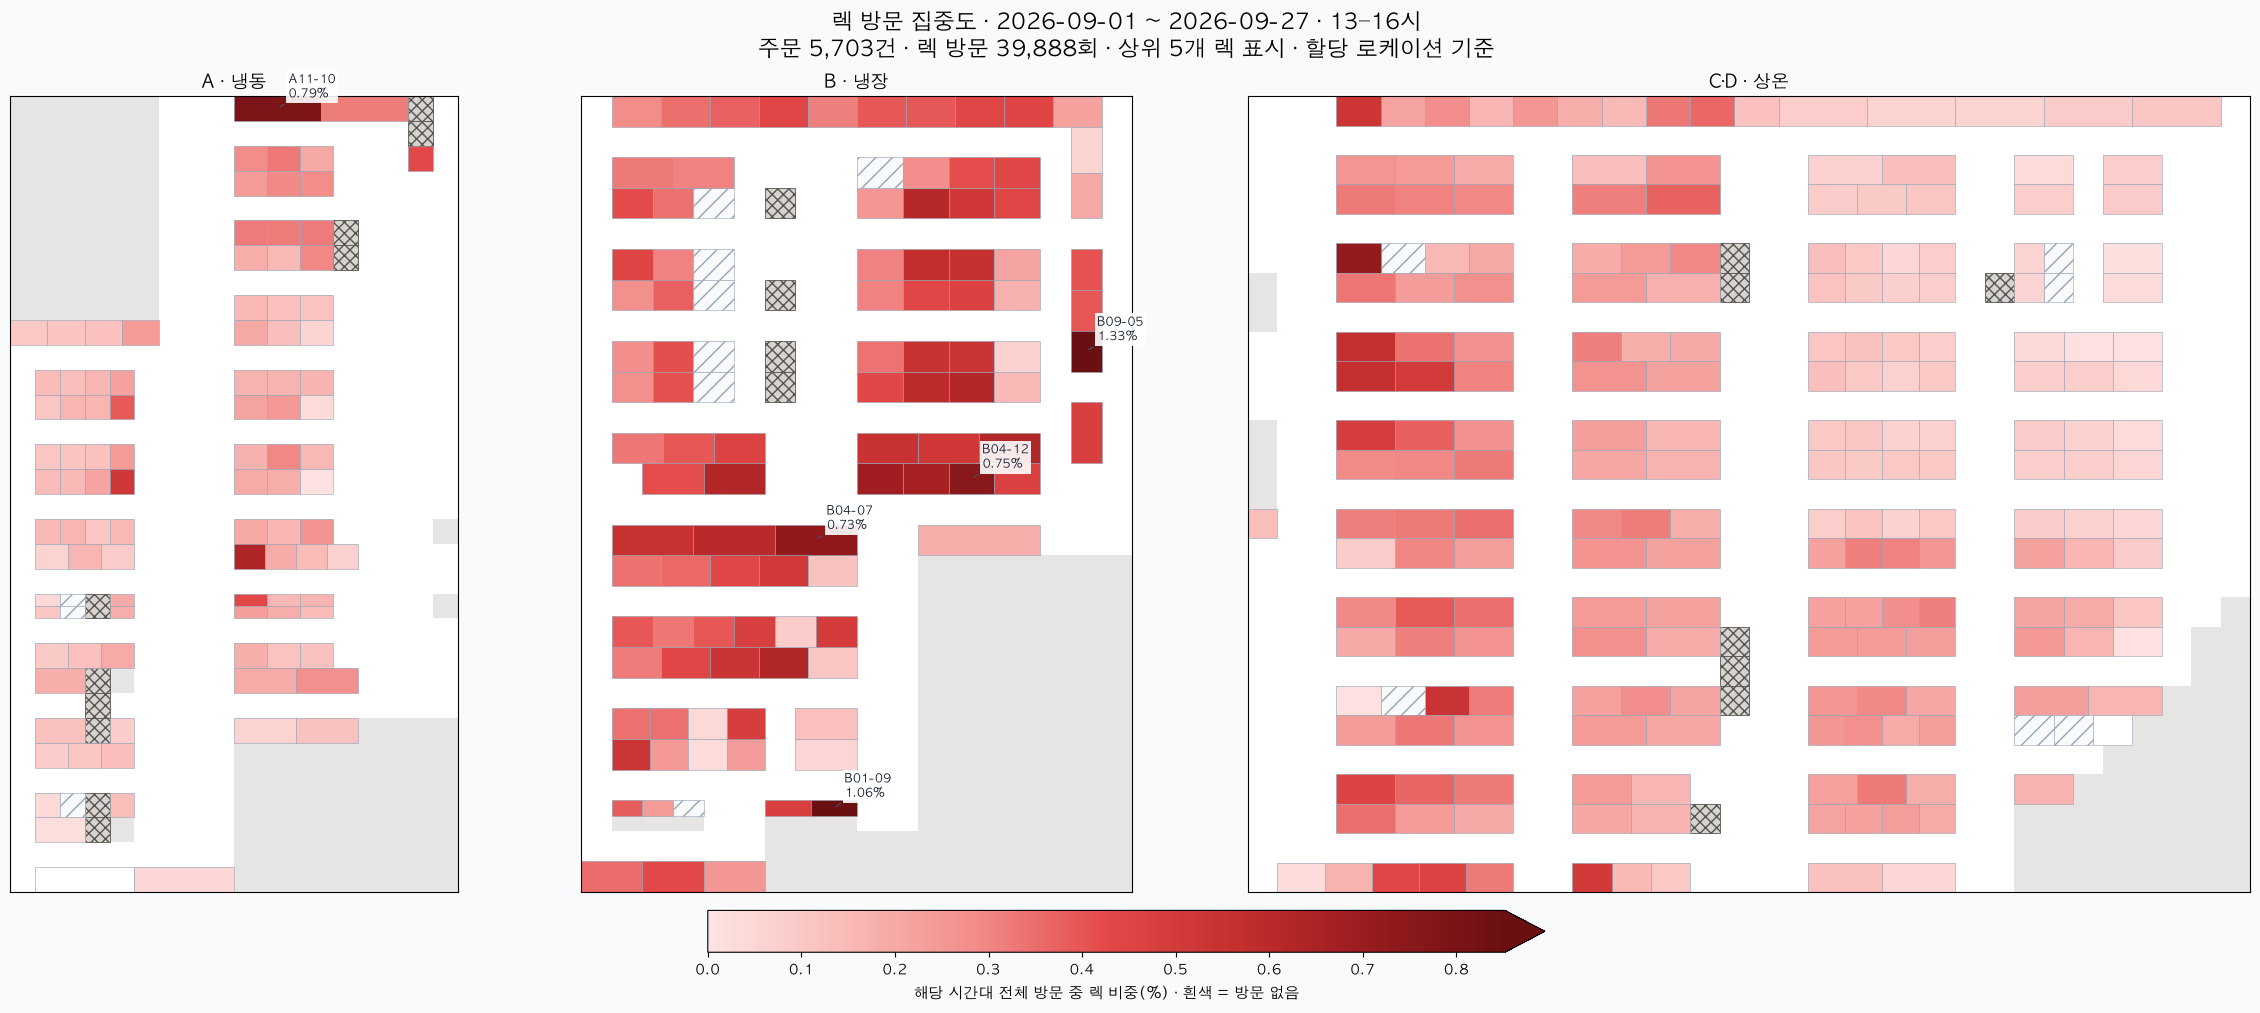

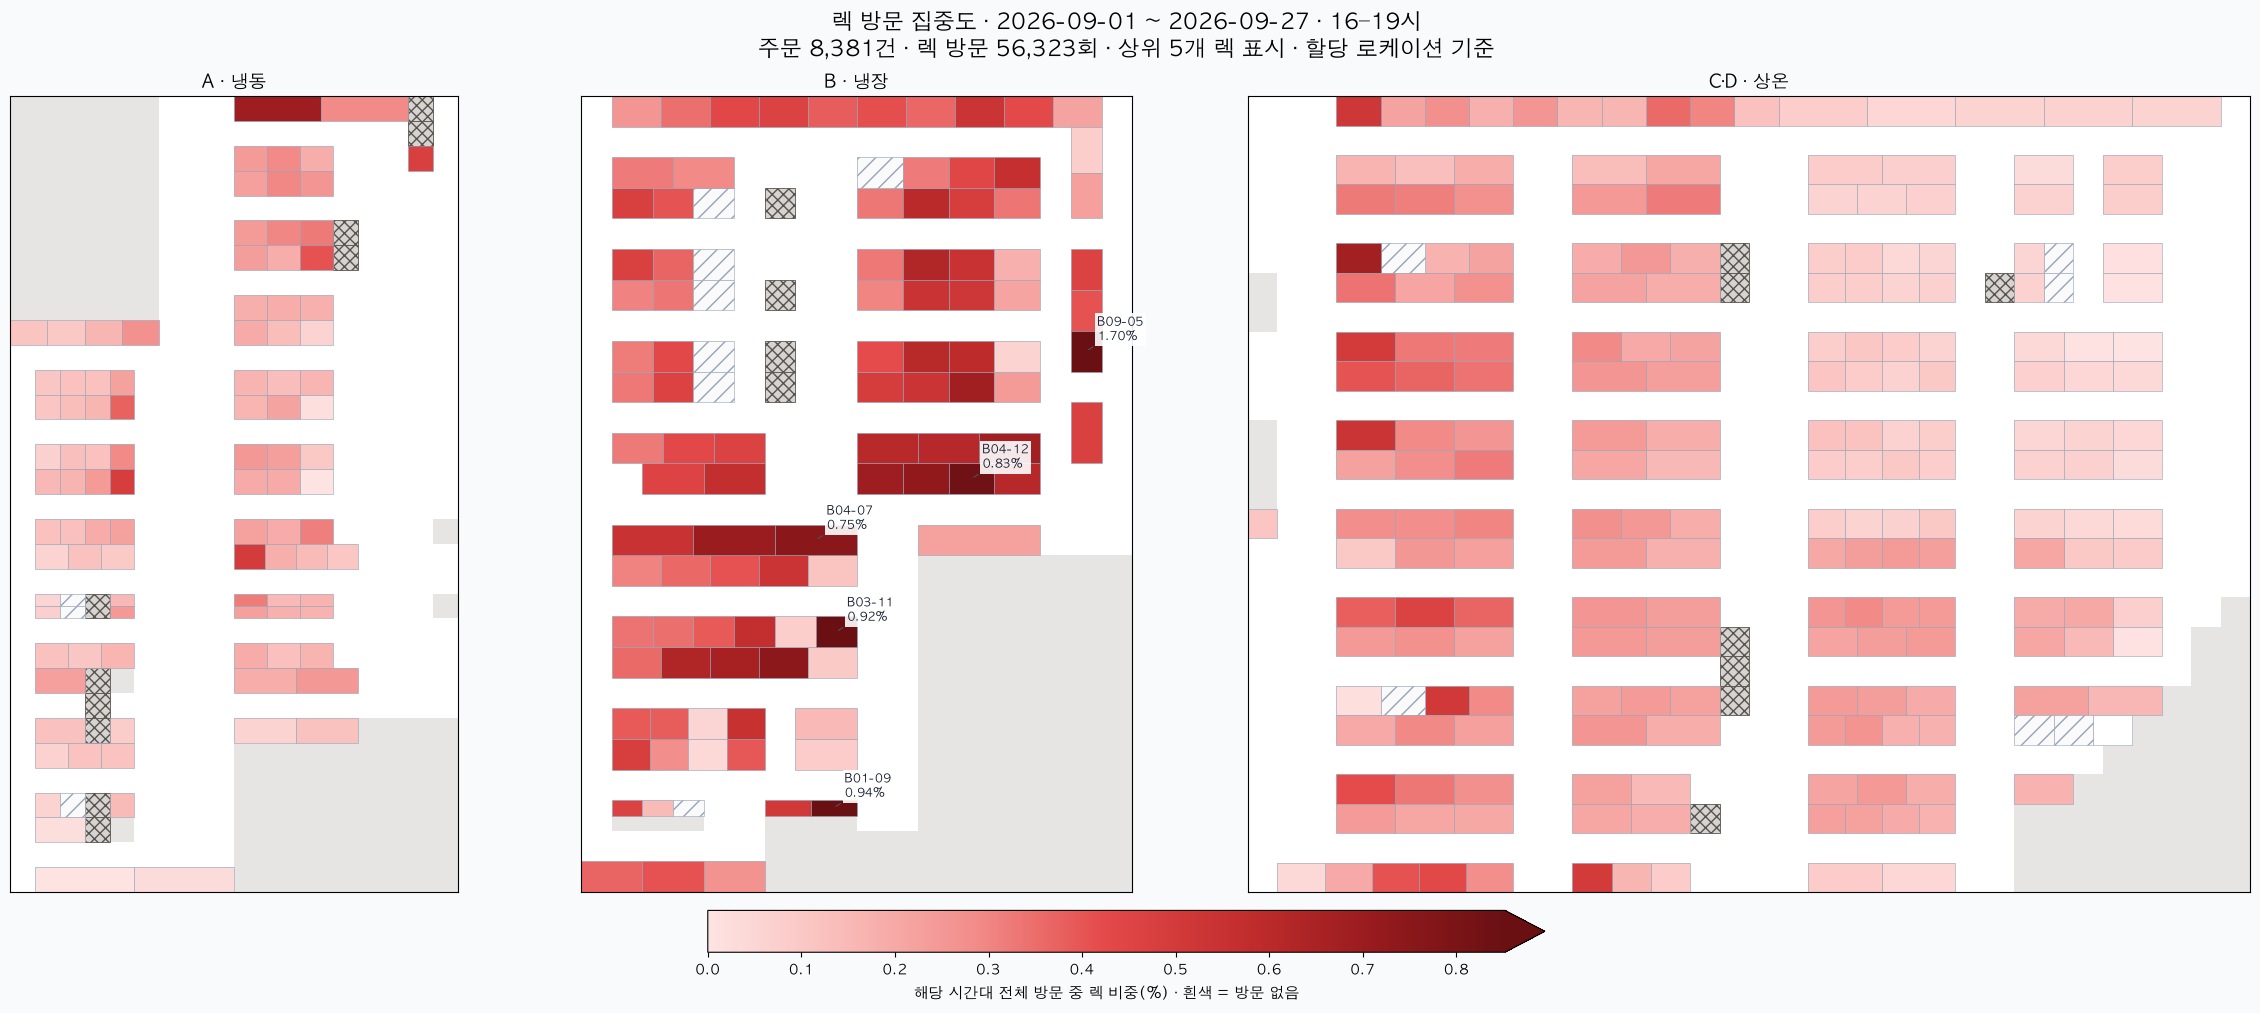

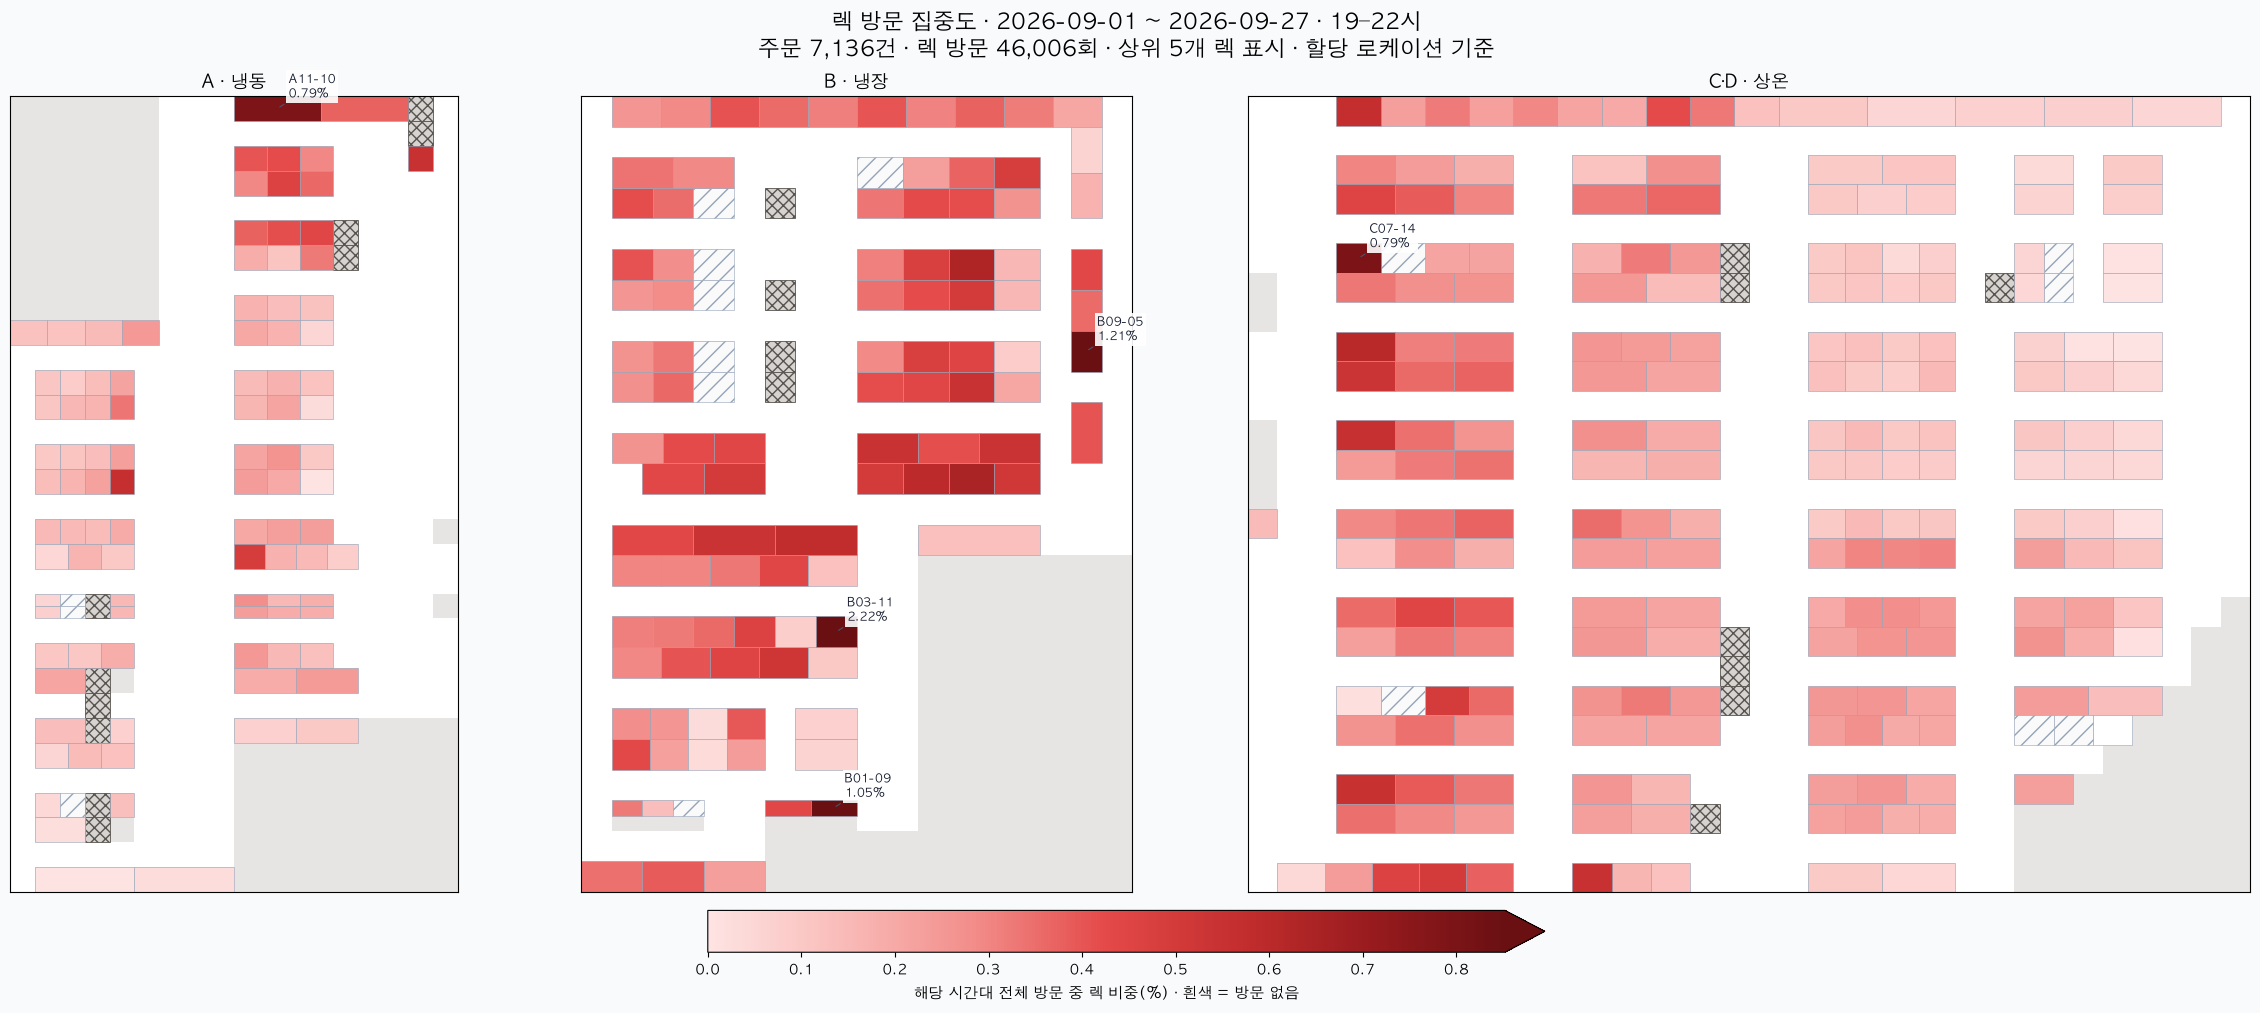

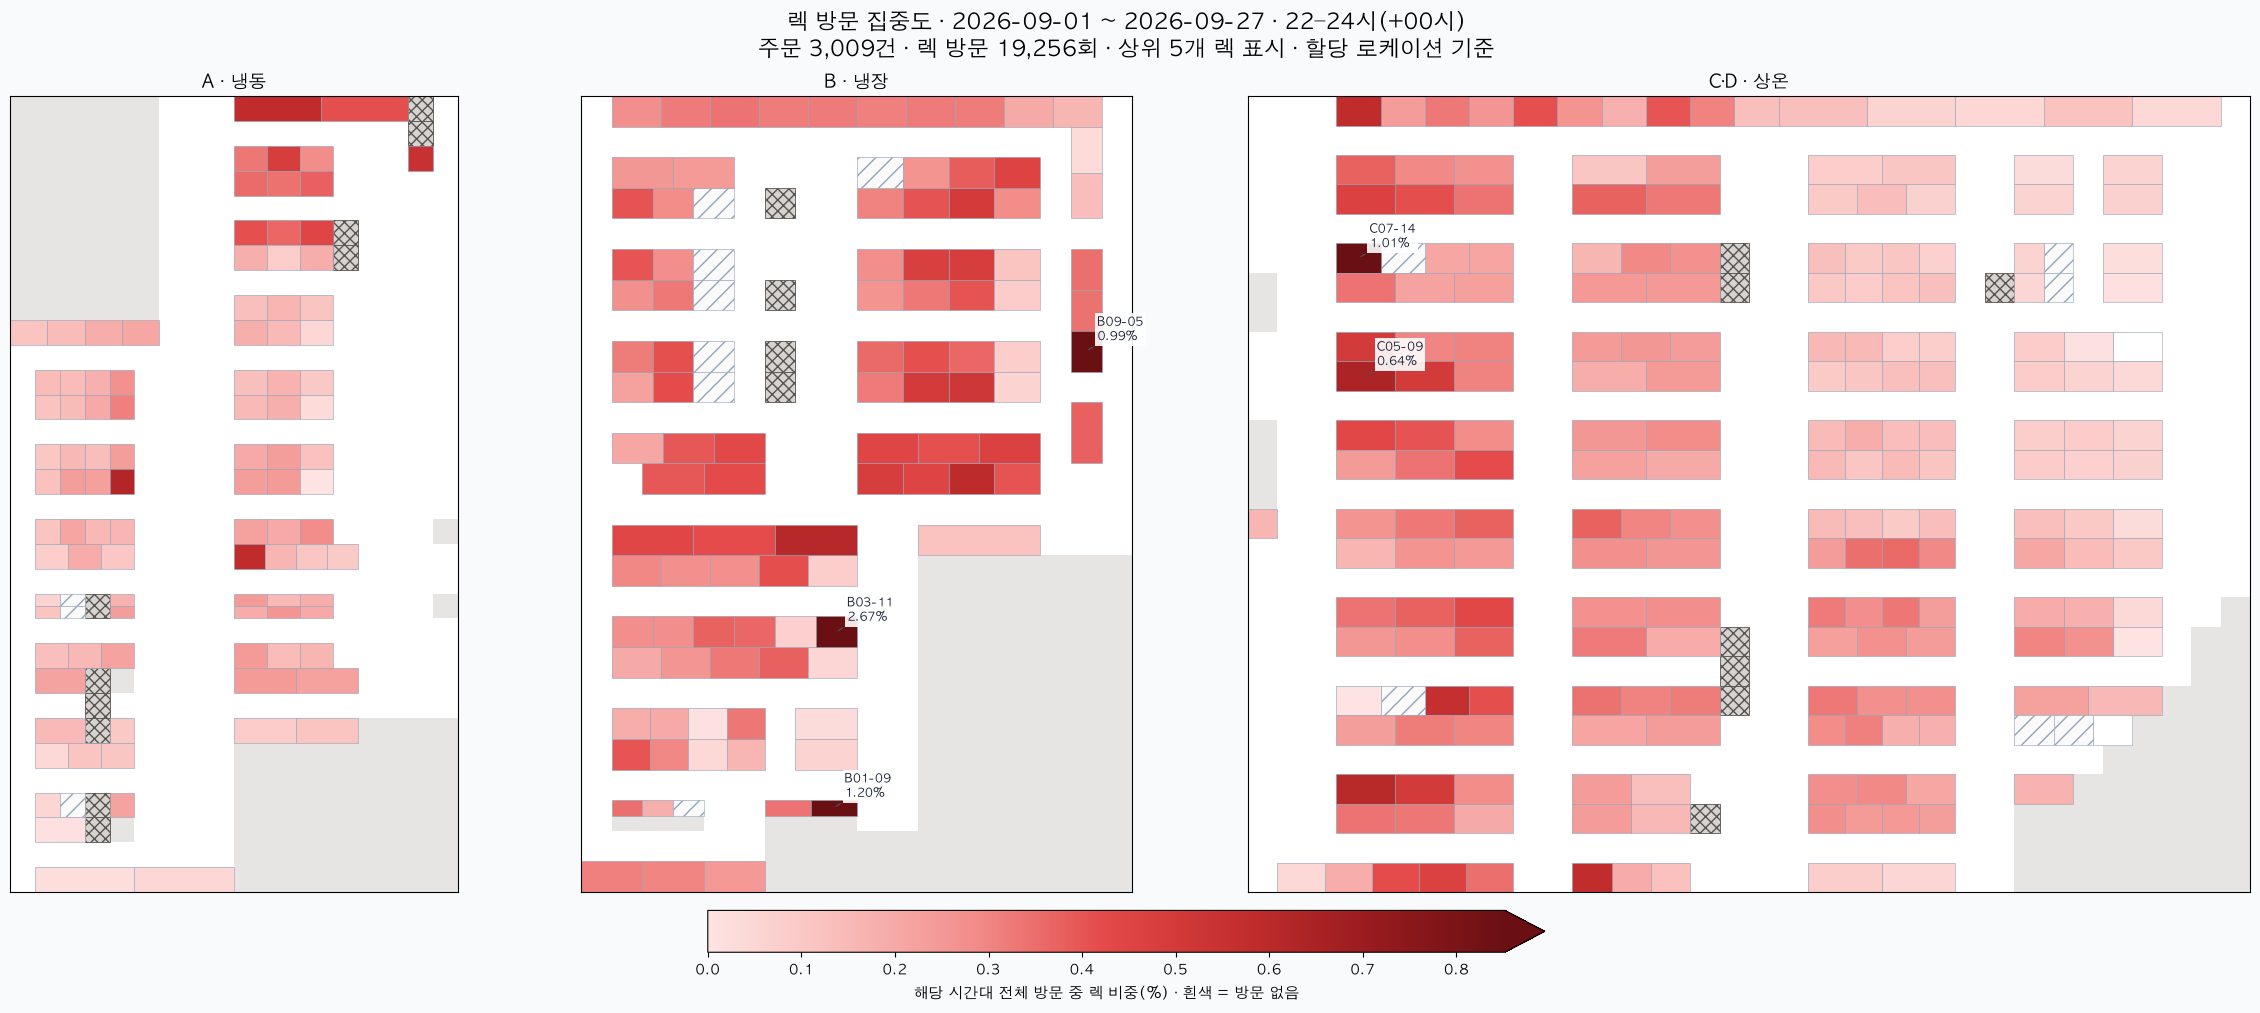

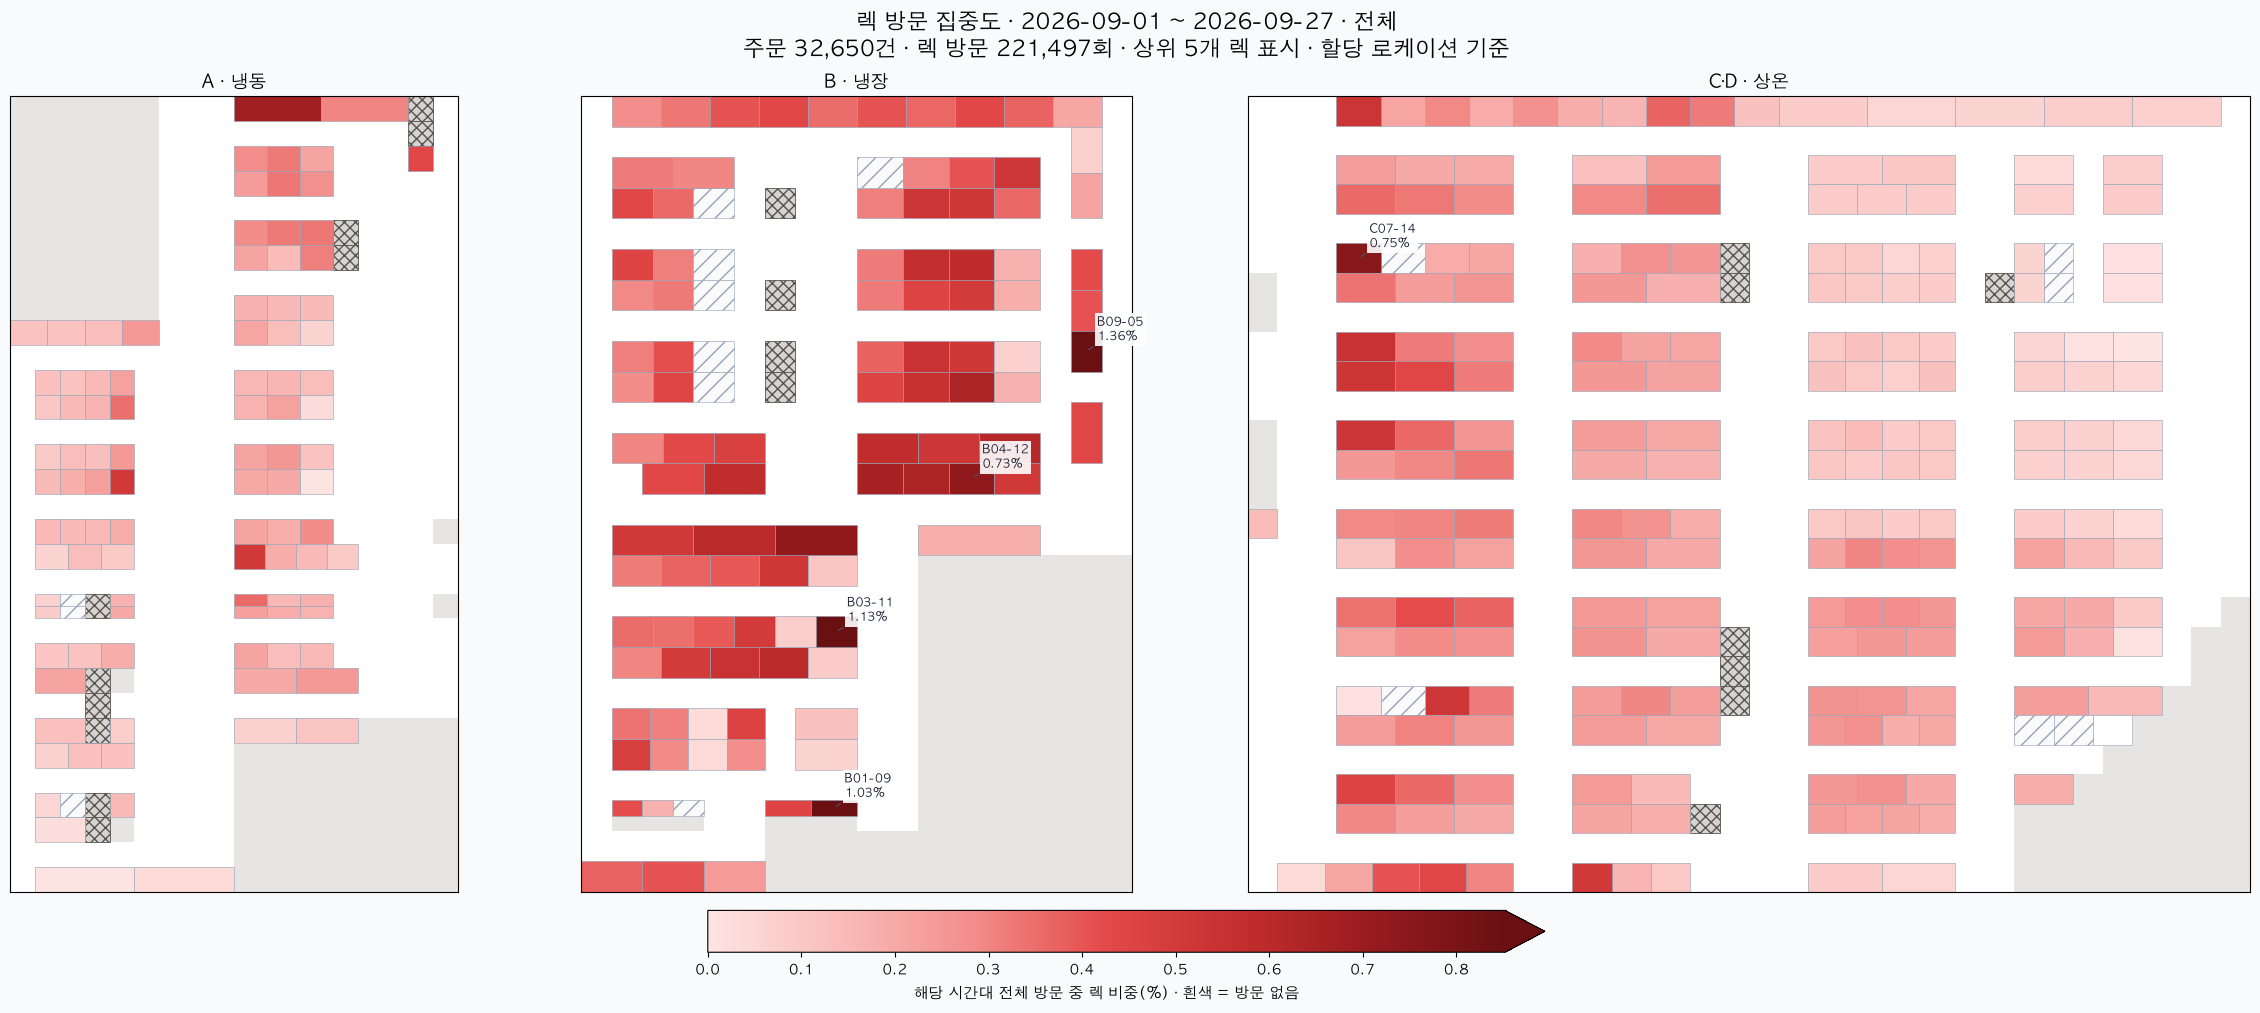

저장: reports/mfc_rack_visits_by_hour/2026-09-01_2026-09-27


,주문 수,렉 방문,방문 렉 수,상위 10% 렉의 방문 비중(%)
band,,,,
07–10시,3054,21669,400,25.5
10–13시,5390,38355,400,24.7
13–16시,5703,39888,400,24.2
16–19시,8381,56323,401,25.9
19–22시,7136,46006,401,24.3
22–24시(+00시),3009,19256,400,24.0
전체,32650,221497,401,24.4


In [4]:
for period in results:
    folder = save_period(period)
    print("저장:", folder.relative_to(ROOT))
    display(results[period]["summary"])

## 4. 기간 비교 · 시간대별 상위 10개 렉

In [5]:
for period in results:
    print(f"{period[0]} ~ {period[1]}")
    display(pd.read_csv(OUTPUT / f"{period[0]}_{period[1]}" / "top10.csv", index_col=0))

2026-08-10 ~ 2026-08-31


,07–10시,10–13시,13–16시,16–19시,19–22시,22–24시(+00시),전체
순위,,,,,,,
1,B09-05 (1.41%),B09-05 (1.57%),B09-05 (1.58%),B09-05 (1.88%),B09-05 (1.49%),B03-11 (1.53%),B09-05 (1.57%)
2,B01-07 (0.88%),A06-08 (0.94%),A06-08 (1.05%),A06-08 (0.92%),A06-08 (1.09%),A06-08 (1.27%),A06-08 (1.00%)
3,B04-07 (0.88%),B04-07 (0.87%),A11-10 (0.90%),A11-10 (0.91%),A11-10 (1.07%),A12-00 (1.12%),A11-10 (0.90%)
4,B04-10 (0.83%),B01-07 (0.84%),B09-03 (0.87%),B04-07 (0.90%),A12-00 (1.03%),A11-10 (1.06%),A12-00 (0.84%)
5,B07-11 (0.79%),B04-03 (0.82%),A12-00 (0.86%),B01-07 (0.86%),A05-08 (0.91%),A05-08 (1.03%),A05-08 (0.82%)
6,B04-03 (0.76%),C00-10 (0.81%),B04-07 (0.84%),A05-08 (0.85%),B03-11 (0.91%),B03-09 (1.03%),C00-10 (0.81%)
7,A06-08 (0.74%),C00-12 (0.77%),A05-08 (0.82%),A12-00 (0.83%),C00-10 (0.87%),B09-05 (1.01%),B04-07 (0.80%)
8,B04-12 (0.74%),B09-03 (0.76%),C00-10 (0.79%),C00-10 (0.80%),C00-12 (0.81%),C00-10 (0.86%),B01-07 (0.78%)
9,A05-08 (0.71%),B04-10 (0.76%),B01-07 (0.78%),B02-08 (0.77%),B03-09 (0.76%),C08-15 (0.85%),B09-03 (0.72%)


2026-09-01 ~ 2026-09-27


,07–10시,10–13시,13–16시,16–19시,19–22시,22–24시(+00시),전체
순위,,,,,,,
1,B09-05 (1.18%),B09-05 (1.34%),B09-05 (1.33%),B09-05 (1.70%),B03-11 (2.22%),B03-11 (2.67%),B09-05 (1.36%)
2,B01-09 (1.05%),B01-09 (0.98%),B01-09 (1.06%),B01-09 (0.94%),B09-05 (1.21%),B01-09 (1.20%),B03-11 (1.13%)
3,B04-07 (0.88%),B04-07 (0.85%),A11-10 (0.79%),B03-11 (0.92%),B01-09 (1.05%),C07-14 (1.01%),B01-09 (1.03%)
4,B04-08 (0.83%),B04-08 (0.80%),B04-12 (0.75%),B04-12 (0.83%),C07-14 (0.79%),B09-05 (0.99%),C07-14 (0.75%)
5,C07-14 (0.79%),B05-12 (0.77%),B04-07 (0.73%),B04-07 (0.75%),A11-10 (0.79%),C05-09 (0.64%),B04-12 (0.73%)
6,B04-12 (0.73%),B04-12 (0.75%),C07-14 (0.72%),B02-08 (0.75%),B04-12 (0.65%),A06-08 (0.62%),B04-07 (0.73%)
7,B05-12 (0.70%),C07-14 (0.69%),B04-08 (0.68%),B04-10 (0.73%),B07-11 (0.63%),B04-07 (0.61%),A11-10 (0.68%)
8,B05-07 (0.70%),B04-06 (0.67%),B04-10 (0.66%),B04-05 (0.70%),C06-12 (0.60%),C01-10 (0.61%),B04-08 (0.66%)
9,B07-09 (0.69%),B04-10 (0.65%),A05-08 (0.63%),A11-10 (0.69%),B04-10 (0.59%),B04-12 (0.59%),B04-10 (0.65%)
